# Part 8: Nonlinear Observation Functions

Every part up to now has observed the state through a **linear** map. The whiteboard model from
the supervision replaces it with an arbitrary one,

$$x_{t+1} = b\,x_t + U_t, \qquad y_t = f(x_t) + \varepsilon_t,
\qquad U_t \sim N(0, Q I_d), \quad \varepsilon_t \sim \text{(Gaussian or Student-}t), $$

with $f$ such as $[x + \cos x,\, x]$, $|x|$, $\log(1+x^2)$, $e^x$, $[\cos x, \sin x]$, or a
bearing. This notebook runs **41 observation functions** through the filter and asks what, if
anything, the shape of $f$ costs.

### The question it is actually for

Part 7 established that Del Moral & Gerber (2026) §5.3.3 makes the $r$-dimensional observation
collapse to $d$ dimensions **under a Gaussian potential**, so that extra coordinates leave no
trace — and that under a Student-$t$ they do, at a price up to $4.7\times$. But §5.3.1 requires
something of $f$ that is easy to misread:

> the reduction needs the **image** $f(\mathbb{R}^d)$ to lie in a $d$-dimensional affine subspace.

That is *not* the same as $f$ being linear. $f(x) = [x^3, x^3]$ is nonlinear and its image is still
a line, so the reduction **must still hold**; $f(x) = [x + \cos x, x]$ is a bounded perturbation of
a linear map and its image is a curve, so it **must fail**. The two are routinely conflated. The
registry in `observation_models.py` is built so that the distinction can be measured rather than
asserted, and Section 1 measures it.

### The three filters compared at every cell

| variant | what it does | what it tests |
|---|---|---|
| `full` | the correct $f$, the correct potential, all $r$ coordinates | the baseline |
| `proj` | replaces $y_t$ by $\hat z_t$, the §5.3.2 projection onto $V$ | does the reduction cost anything? |
| `affine` | replaces $f$ by its best affine fit, then projects | what does *assuming* §5.3.1 cost? |

The third is the one with no counterpart in Parts 1–8. When the image is curved the reduction is
not available, but a practitioner's reflex is to linearise and apply it anyway. `affine` is exactly
that reflex, scored against the exact posterior of the **true** model, so the assumption carries a
number.

### What is measured, and against what

Once $f$ is nonlinear the model is not linear-Gaussian, so the Kalman filter is **not** its exact
filter and cannot be the benchmark. The benchmark is the grid filter of `observation_models.py`,
which carries the exact recursion out numerically — `grid_filter_obs` for $d = 1$ and
`grid_filter_obs_2d`, added for this part, for $d = 2$. Section 3 validates both against the Kalman
filter where both apply, and checks convergence in the grid spacing.

The error metric is the **Kolmogorov distance** of Part 9: bounded by 1, scale-free, and calibrated
($1.017/\sqrt{N}$ for an exact sample, so a cloud scoring $D$ is worth $(1.017/D)^2$ independent
draws). Scale-freeness is not a nicety here. Several of these $f$ are **non-injective** — $|x|$,
$x^2$, $\cos x$ — so the exact posterior is multimodal and symmetric, its mean sits near zero, and
**no comparison of posterior means can be a measure of accuracy**. Section 7 makes that concrete.

---
## Section 0 — Setup

`QUICK = True` runs a reduced grid in about a minute.

In [1]:
import math
import time

import numpy as np
import matplotlib.pyplot as plt

import observation_models as om
from filters import kalman_filter_md, unit_directions

QUICK = False

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})

# --- the model -------------------------------------------------------------
B_MAIN = 0.9      # spectral radius of the state recursion
Q      = 1.0      # state noise variance
T      = 300 if not QUICK else 120
N      = 1000
H1     = 0.0005 if not QUICK else 0.004    # grid spacing, d = 1
H2     = 0.08   if not QUICK else 0.15     # grid spacing, d = 2
SEED_D = 7        # data
SEED_F = 11       # filter

POTENTIALS = [("Gaussian",      om.GaussianPotential()),
              ("t joint nu=5",  om.StudentPotentialJoint(5)),
              ("t joint nu=1",  om.StudentPotentialJoint(1)),
              ("t indep nu=5",  om.StudentPotentialIndep(5))]
if QUICK:
    POTENTIALS = POTENTIALS[:2]

D1 = [f for f in om.REGISTRY.values() if f.d == 1]
D2 = [f for f in om.REGISTRY.values() if f.d == 2]
print(f"registry: {len(om.REGISTRY)} functions  ({len(D1)} with d=1, {len(D2)} with d=2)")
for g in sorted({f.group for f in om.REGISTRY.values()}):
    names = [f.name for f in om.REGISTRY.values() if f.group == g]
    print(f"  {g:28s} {len(names):2d}  {', '.join(names)}")
print(f"\nT={T}  N={N}  b={B_MAIN}  h(1d)={H1}  h(2d)={H2}  "
      f"potentials={len(POTENTIALS)}")

registry: 41 functions  (31 with d=1, 10 with d=2)
  A: linear image               7  lin_xx, lin_xx_offset, lin_x3x, lin_x_minusx, lin_xxx, cube_both, contract_both
  B1: curved, bi-Lipschitz     10  cos_x, xpluscos_x, sin_x, wiggle_x, tanh_x, arctan_x, abs_x, log1px2_x, bump_x, circle
  B2: curved, lower bound only  4  sq_x, cube_x, exp_x, sqrtabs_x
  C: (P1)b violated            10  abs_only, sq_only, log1px2_only, cos_only, exp_only, tanh_only, softsign_only, xpluscos_only, round_only, clip_only
  D: r < d                      4  d2_first, d2_sum, d2_norm, d2_prod
  E: d = 2 nonlinear            6  d2_polar, d2_coupled, d2_xxprod, d2_bearing, d2_range, d2_range_bearing

T=300  N=1000  b=0.9  h(1d)=0.0005  h(2d)=0.08  potentials=4


### Why $b = 0.9$ and not the random walk

The whiteboard model is the random walk, $b = 1$. Section 9 runs it. The main matrix does not, and
the reason is worth stating up front because it is itself a result.

At $b = 1$ the state has no stationary law and wanders — over $T = 300$ steps it reaches
$|x| \approx 44$. For a **superlinear** $f$ the observation then becomes unboundedly informative:
with $f(x) = [x^3, x^3]$ and $\Sigma = I$ the exact posterior standard deviation at $|x| \approx 24$
is $2 \times 10^{-18}$. That is not a filter that performs badly — it is a posterior that **no grid
can resolve and no prior-proposal filter can reach**, so neither the benchmark nor the filter means
anything there. The cell below demonstrates it before the design is settled on.

A stationary state keeps every $f$ inside a bounded window, where the grid resolves every posterior
and the shape of $f$ is the only thing varying. That is what makes the matrix readable.

In [2]:
# The b = 1 pathology, shown rather than asserted.
pot = om.GaussianPotential()
rows = []
for nm, b in [("cube_both", 1.0), ("cube_both", 0.9), ("lin_xx", 1.0), ("lin_xx", 0.9)]:
    fn = om.REGISTRY[nm]
    S = np.eye(fn.r)
    x, y = om.simulate_obs_model(fn, pot, S, T=T, b=b, Q=Q, seed=SEED_D)
    m, v, ll, g, post = om.grid_filter_obs(y, fn, pot, S, b=b, Q=Q, h=0.02,
                                           x_ref=x, return_post=True)
    sd = np.sqrt(np.maximum(v, 0.0))
    ks = []
    out = om.particle_filter_obs(y, fn, pot, S, b=b, Q=Q, N=N, seed=SEED_F,
                                 stat_fn=lambda t, p, w: ks.append(
                                     om.ks_vs_grid(p, w, g, post[t])))
    rows.append((nm, b, np.median(np.abs(x)), np.abs(x).max(),
                 np.median(sd), sd.min(), np.mean(ks), np.mean(out[1]) / N))

print(f"{'f':12s} {'b':>4s} {'|x| med':>8s} {'|x| max':>8s} "
      f"{'post sd med':>12s} {'post sd min':>12s} {'mean KS':>8s} {'ESS/N':>6s}")
for r in rows:
    print(f"{r[0]:12s} {r[1]:4.1f} {r[2]:8.2f} {r[3]:8.2f} "
          f"{r[4]:12.3e} {r[5]:12.3e} {r[6]:8.4f} {r[7]:6.3f}")

f               b  |x| med  |x| max  post sd med  post sd min  mean KS  ESS/N
cube_both     1.0    24.27    43.92    2.091e-18    0.000e+00   0.8127  0.013
cube_both     0.9     1.59     7.25    9.426e-02    5.265e-04   0.1883  0.185
lin_xx        1.0    24.27    43.92    6.050e-01    5.774e-01   0.0470  0.447
lin_xx        0.9     1.59     7.25    6.004e-01    5.774e-01   0.0466  0.459


**Reading.** At $b = 1$ the state reaches $|x| = 43.9$, and there $f(x) = [x^3, x^3]$ with
$\Sigma = I$ gives an exact posterior with median standard deviation $2.1 \times 10^{-18}$ —
underflowing to exactly zero at its narrowest. The filter scores $0.813$ with $\text{ESS}/N = 0.013$,
and Section 0's pilot confirmed that raising $N$ a hundredfold does not move either number.

Nothing about that is a property of the cube. The same $f$ at $b = 0.9$, where the state stays
inside $|x| \le 7.3$, has posterior standard deviation $0.094$ and scores $0.188$. The linear
control $[x, x]$ is untouched by the change ($0.0470$ vs $0.0466$) because its information does not
depend on the state.

So the $b = 1$ failure is **the product of a superlinear $f$ and a nonstationary state**, not of
either alone, and it disables the benchmark as thoroughly as the filter: a posterior of width
$10^{-18}$ is not resolvable on any grid that fits in memory. Section 2 removes the confound by
equalising information, Section 9 then returns to $b = 1$ with that fix in place, and the result
there is different and more interesting than this cell suggests.

---
## Section 1 — The structural census: is the image a subspace?

`om.describe` measures, for each $f$, the facts §5.3.1 and (P1)b depend on, from the function
alone:

* `affine_dim` — the dimension of the smallest affine subspace containing $f(\mathbb{R}^d)$, by an
  SVD of the **centred** sampled image. Centring is what makes $[x, x] + [1, 2]$ come out at 1
  rather than 2: a constant offset is absorbed into $y - b$ and changes nothing.
* `reduces` — `affine_dim <= d` **and** `affine_dim < r`. Both halves matter: the image must fit in
  $d$ dimensions, and there must be something left over to discard. When $r = d$ there is nothing
  to throw away whatever shape $f$ has.
* `lip_lo`, `lip_hi` — empirical Lipschitz constants from above and below. (P1)b asks for
  $0 < c \le C < \infty$; a `lip_lo` near zero means the lower bound fails, a huge `lip_hi` means
  $f$ is not Lipschitz.
* `inj_gap` — the smallest $\|f(x) - f(x')\|$ over states more than 1 apart. Near zero means the
  likelihood cannot separate two distant states, so the posterior is multimodal.

The `claim_*` columns are what the registry *asserts*. The point of the table is to let the two
disagree.

In [3]:
t0 = time.time()
desc = [om.describe(fn) for fn in om.REGISTRY.values()]
print(f"({time.time()-t0:.0f}s)\n")
print(f"{'f':18s} {'group':28s} {'d':>1s} {'r':>1s} {'aff':>3s} {'red':>5s} "
      f"{'lip_lo':>8s} {'lip_hi':>9s} {'inj_gap':>8s} {'claim':>6s}")
print("-" * 104)
last = None
for row in desc:
    if row["group"] != last:
        print()
        last = row["group"]
    print(f"{row['name']:18s} {row['group']:28s} {row['d']} {row['r']} "
          f"{row['affine_dim']:3d} {str(row['reduces']):>5s} "
          f"{row['lip_lo']:8.2e} {row['lip_hi']:9.2e} {row['inj_gap']:8.2e} "
          f"{str(row['claim_linear_image']):>6s}")

# Aliases: two registry entries can be the SAME function under two names
# (polar coordinates and the paper's range/bearing tracking model are one map
# written two ways). Detected rather than assumed, so that duplicated rows
# below are not read as two independent confirmations.
import itertools
_rng = np.random.default_rng(0)
_probe = {d: _rng.uniform(-4, 4, size=(300, d)) for d in (1, 2)}
_sig = {fn.name: (fn.d, fn.r, np.round(fn(_probe[fn.d]), 12).tobytes())
        for fn in om.REGISTRY.values()}
ALIAS = {}
for a, b in itertools.combinations(_sig, 2):
    if _sig[a] == _sig[b]:
        ALIAS.setdefault(a, []).append(b)
print(f"\ndistinct functions: {len(om.REGISTRY) - sum(len(v) for v in ALIAS.values())} "
      f"of {len(om.REGISTRY)} entries")
for a, bs in ALIAS.items():
    print(f"  alias: {a} == {', '.join(bs)}")

mismatch = [r for r in desc
            if r["claim_linear_image"] != (r["affine_dim"] <= r["d"])]
print(f"\nclaim vs measurement mismatches: {len(mismatch)}"
      + ("" if not mismatch else "  " + ", ".join(r["name"] for r in mismatch)))

print("\nthe separation that matters -- nonlinear f with a linear image:")
for r in desc:
    fn = om.REGISTRY[r["name"]]
    if r["affine_dim"] <= r["d"] and r["lip_hi"] > 10 * max(r["lip_lo"], 1e-12) \
            and fn.r > 1:
        print(f"  {r['name']:16s} aff={r['affine_dim']} r={r['r']} "
              f"lip {r['lip_lo']:.2e} .. {r['lip_hi']:.2e}  reduces={r['reduces']}")

(4s)

f                  group                        d r aff   red   lip_lo    lip_hi  inj_gap  claim
--------------------------------------------------------------------------------------------------------

lin_xx             A: linear image              1 2   1  True 1.41e+00  1.41e+00 1.41e+00   True
lin_xx_offset      A: linear image              1 2   1  True 1.41e+00  1.41e+00 1.41e+00   True
lin_x3x            A: linear image              1 2   1  True 3.16e+00  3.16e+00 3.16e+00   True
lin_x_minusx       A: linear image              1 2   1  True 1.41e+00  1.41e+00 1.41e+00   True
lin_xxx            A: linear image              1 3   1  True 1.73e+00  1.73e+00 1.73e+00   True
cube_both          A: linear image              1 2   1  True 9.75e-10  1.53e+02 3.54e-01   True
contract_both      A: linear image              1 2   1  True 7.07e-01  2.12e+00 7.36e-01   True

cos_x              B1: curved, bi-Lipschitz     1 2   2 False 1.00e+00  1.41e+00 1.00e+00  False
xpluscos_x    

**Conclusion of Section 1.** The distinction §5.3.1 actually turns on is measurable, and it
separates exactly where it should.

**Nonlinear is not the same as "breaks the reduction".** `cube_both`, $f(x) = [x^3, x^3]$, has
measured Lipschitz constants spanning $9.8 \times 10^{-10}$ to $1.5 \times 10^2$ — eleven orders of
magnitude, so it is violently nonlinear and not remotely bi-Lipschitz — and yet `affine_dim` $= 1$
and `reduces` $=$ `True`. Its image is a line. Meanwhile `xpluscos_x`, $[x + \cos x,\, x]$, is
bi-Lipschitz with constants $1.00$ and $2.24$, about as tame as a nonlinear map gets, and
`affine_dim` $= 2$: the reduction is unavailable. **The two properties are independent, and the one
§5.3.1 needs is the one about the image.**

`lin_xx_offset` confirms that the centring in `image_dimension` is doing its job:
$[x, x] + [1, 2]$ returns `affine_dim` $= 1$, not 2, because a constant offset is absorbed into
$y - b$.

**The registry's own claims are wrong in 7 of 41 cases**, all of them $d = 2$: `d2_norm`,
`d2_prod`, `d2_polar`, `d2_coupled`, `d2_bearing`, `d2_range`, `d2_range_bearing`. The flag was
hand-set per entry; the measurement overrules it. This is the reason the census exists.

Two further facts the table settles:

* **`reduces` is `False` for every $r = d$ function**, whatever its shape, because the second half
  of the condition (`affine_dim < r`) fails — there is nothing left to discard. Only the seven
  group-A functions, which have $r > d$ **and** a linear image, can be reduced at all.
* **The registry holds 39 distinct maps, not 41.** `d2_norm` $\equiv$ `d2_range` and
  `d2_polar` $\equiv$ `d2_range_bearing` are the same functions under two names — a norm is a range,
  and polar coordinates are range-and-bearing. Detected rather than assumed, so the duplicated rows
  in Section 8 are not misread as independent corroboration.

The near-zero `inj_gap` column marks the functions whose posterior is multimodal: $\cos x$ at
$8.4 \times 10^{-9}$, $|x|$ at $6.4 \times 10^{-7}$, the circle at $4.1 \times 10^{-7}$, and
`clip_only` at exactly $0$ — censoring destroys information outright. Section 7 is about what that
does to any error measure built on posterior means.

---
## Section 2 — Equalising the information

Part 7's lesson was that comparing filters at different observation precisions measures the
precision, not the thing under study. A nonlinear $f$ makes that trap unavoidable, because it sets
its own precision pointwise: for a Gaussian potential with $\Sigma = R_0 I_r$,

$$\mathcal{I}(x) = J(x)^\top J(x) / R_0, \qquad J = \partial f / \partial x,$$

so at $\Sigma = I$ the cubic $[x^3, x^3]$ is $18x^4$ times as informative as $[x, x]$. Running every
$f$ at a common $\Sigma$ would be a study of $\|J\|^2$ wearing the costume of a study of shape.

`om.information_scale` picks $R_0$ so that the **median** $\|J\|_F^2$ over the states actually
visited hits a target, defaulting to $r$ — which leaves $\Sigma = I$ exactly for the replication
baseline $[x, \dots, x]$, keeping Part 7's numbers comparable.

Equalising the median does **not** equalise the range, and the spread column below is a result in
its own right: it says how far from "a fixed observation precision" each $f$ really is.

In [4]:
SCALE = {}
print(f"{'f':18s} {'r':>1s} {'R0':>10s} {'||J||^2 med':>12s} "
      f"{'p10':>10s} {'p90':>10s} {'spread':>10s}")
print("-" * 76)
for fn in om.REGISTRY.values():
    R0, med, lo, hi = om.information_scale(fn, b=B_MAIN, Q=Q)
    SCALE[fn.name] = R0
    spread = hi / lo if lo > 0 else np.inf
    print(f"{fn.name:18s} {fn.r} {R0:10.4g} {med:12.4g} "
          f"{lo:10.3g} {hi:10.3g} {spread:10.3g}")

flat = [n for n in SCALE if om.information_scale(om.REGISTRY[n], b=B_MAIN)[1] <= 0]
print(f"\nf with zero local information (nothing to equalise, Sigma left at I): "
      f"{flat if flat else 'none'}")

f                  r         R0  ||J||^2 med        p10        p90     spread
----------------------------------------------------------------------------
lin_xx             2          1            2          2          2          1
lin_xx_offset      2          1            2          2          2          1
lin_x3x            2          5           10         10         10          1
lin_x_minusx       2          1            2          2          2          1
lin_xxx            3          1            3          3          3          1
cube_both          2       52.9        105.8      0.188   3.64e+03   1.94e+04
contract_both      2      1.123        2.246      0.567       4.36       7.69
cos_x              2     0.7523        1.505       1.03       1.98       1.91
xpluscos_x         2      1.056        2.113          1       4.83       4.82
sin_x              2     0.7477        1.495       1.02       1.97       1.92
wiggle_x           2       2.07         4.14       1.17        7.

**Conclusion of Section 2.** The spread column shows how large the confound would have been.

At a common $\Sigma = I$ the functions in this registry differ in median information by more than
three orders of magnitude — $\|J\|_F^2$ runs from $0.027$ for `tanh_only` to $106$ for `cube_both`.
Any experiment comparing them at a fixed $\Sigma$ would have been ranking $\|J\|^2$.

Equalising the median leaves $\Sigma = I$ untouched for the replication baselines
($[x,x]$, $[x,x,x]$, $|x|$, $[|x|, x]$, `d2_first`, `d2_norm`), so Part 7's numbers stay comparable,
and rescales the rest — by $52.9\times$ for `cube_both` and $26.9\times$ for `cube_x` downward in
precision, by $38\times$ upward for `tanh_only`.

**What it cannot do is equalise the range**, and the spread is a result in its own right:

| $f$ | spread of $\|J\|_F^2$ |
|---|---|
| $[x, x]$, $\|x\|$, circle | $1\times$ (exactly state-independent) |
| $[x + \cos x,\, x]$ | $4.8\times$ |
| $[x^2, x]$ | $41\times$ |
| $[x^3, x^3]$ | $1.9 \times 10^{4}\times$ |
| $e^x$ | $1.2 \times 10^{5}\times$ |
| $\tanh x$ | $1.8 \times 10^{5}\times$ |
| $\mathrm{round}(x)$, $\mathrm{clip}(x, \pm 3)$ | $\infty$ |

"Fixed observation precision" is simply not a property a nonlinear $f$ has. For $\tanh$ the
information collapses in the saturated tails; for $e^x$ it explodes to the right; for
$\mathrm{round}$ it is **identically zero** between jumps, so there is nothing to equalise and
$\Sigma$ is left at $I$ — the function carries information only through its discontinuities, which
the experiment should record rather than normalise away.

The two decades of residual spread in the superlinear cases are why Section 4 carries a resolution
guard and Section 9 finds two functions unusable at $b = 1$ even after this correction.

---
## Section 3 — Validating the benchmark

Three checks, because every number after this depends on the grid filter being the exact posterior
and not an approximation of one.

1. **$d = 1$ against the Kalman filter**, on the linear-Gaussian case where both apply.
2. **$d = 2$ against the Kalman filter** — `grid_filter_obs_2d` is new in this part. Its predict
   step factorises the isotropic $N(0, Q I_2)$ kernel into two one-dimensional convolutions, which
   is what makes an exact $d = 2$ benchmark affordable at all: $O(G^2 \log G)$ per step rather than
   $O(G^4)$.
3. **Convergence in $h$** on the four cells with the narrowest posteriors, which are the only ones
   where resolution could plausibly bite.

Note what check 2 shows about $b$: at $b = 1$ the predict step is a pure convolution and the grid
filter is exact to round-off, while at $b \ne 1$ the push-forward $x \mapsto bx$ is done by
interpolation and costs a few parts in $10^4$. The main matrix runs at $b = 0.9$, so this is the
error floor it inherits — three orders of magnitude below any Kolmogorov distance measured below,
but interpolation error rather than round-off, and worth knowing.

In [5]:
pot = om.GaussianPotential()

# --- check 1: d = 1 --------------------------------------------------------
fn = om.REGISTRY["lin_xx"]
print("d = 1, f(x) = [x, x], Gaussian:")
for b in (1.0, B_MAIN):
    x, y = om.simulate_obs_model(fn, pot, np.eye(2), T=60, b=b, Q=Q, seed=3)
    m, v, ll, g = om.grid_filter_obs(y, fn, pot, np.eye(2), b=b, Q=Q, h=0.002, x_ref=x)
    km, kP = kalman_filter_md(y, np.array([[b]]), np.array([[Q]]),
                              np.ones((2, 1)), np.eye(2))
    print(f"  b={b:4.1f}  mean err {np.abs(m - km[:, 0]).max():.2e}   "
          f"var err {np.abs(v - kP[:, 0, 0]).max():.2e}")

# --- check 2: d = 2 --------------------------------------------------------
ident = om.ObsFunction("d2_ident", 2, 2, lambda z: z, r"[x_1,\,x_2]",
                       linear_image=True, bi_lipschitz="yes", group="control")
print("\nd = 2, f(x) = [x_1, x_2], Gaussian:")
for b in (1.0, B_MAIN):
    x, y = om.simulate_obs_model(ident, pot, np.eye(2), T=60, b=b, Q=Q, seed=3)
    for h in (2 * H2, H2):
        m2, C2, ll2, g2 = om.grid_filter_obs_2d(y, ident, pot, np.eye(2), b=b, Q=Q,
                                                h=h, x_ref=x)
        km, kP = kalman_filter_md(y, b * np.eye(2), Q * np.eye(2),
                                  np.eye(2), np.eye(2))
        print(f"  b={b:4.1f} h={h:5.3f} G={len(g2):4d}  "
              f"mean err {np.abs(m2 - km).max():.2e}   "
              f"var err {np.abs(C2[:, 0, 0] - kP[:, 0, 0]).max():.2e}")

# --- check 3: convergence in h --------------------------------------------
print(f"\nconvergence in h (b={B_MAIN}, Gaussian), narrowest-posterior cells:")
for nm in ["exp_only", "exp_x", "cube_both", "cube_x"]:
    fnc = om.REGISTRY[nm]
    S = SCALE[nm] * np.eye(fnc.r)
    x, y = om.simulate_obs_model(fnc, pot, S, T=T, b=B_MAIN, Q=Q, seed=SEED_D)
    prev = None
    for h in sorted({0.01, 0.002, H1}, reverse=True):
        m, v, ll, g, post = om.grid_filter_obs(y, fnc, pot, S, b=B_MAIN, Q=Q,
                                               h=h, x_ref=x, return_post=True)
        ks = []
        om.particle_filter_obs(y, fnc, pot, S, b=B_MAIN, Q=Q, N=N, seed=SEED_F,
                               stat_fn=lambda t, p, w: ks.append(
                                   om.ks_vs_grid(p, w, g, post[t])))
        sdmin = float(np.sqrt(np.maximum(v, 0)).min())
        d = "" if prev is None else f"  change {np.mean(ks) - prev:+.5f}"
        print(f"  {nm:10s} h={h:7.4f} G={len(g):7d} sd_min={sdmin:.2e} "
              f"sd_min/h={sdmin/h:7.1f} meanKS={np.mean(ks):.5f}{d}")
        prev = np.mean(ks)

d = 1, f(x) = [x, x], Gaussian:
  b= 1.0  mean err 7.17e-14   var err 1.05e-14
  b= 0.9  mean err 3.07e-07   var err 4.51e-08

d = 2, f(x) = [x_1, x_2], Gaussian:
  b= 1.0 h=0.160 G= 197  mean err 4.44e-15   var err 1.22e-15


  b= 1.0 h=0.080 G= 393  mean err 4.44e-15   var err 1.22e-15
  b= 0.9 h=0.160 G= 156  mean err 2.58e-03   var err 7.99e-04


  b= 0.9 h=0.080 G= 311  mean err 6.50e-04   var err 1.59e-04

convergence in h (b=0.9, Gaussian), narrowest-posterior cells:
  exp_only   h= 0.0100 G=   3451 sd_min=5.29e-04 sd_min/h=    0.1 meanKS=0.04931


  exp_only   h= 0.0020 G=  17250 sd_min=2.31e-03 sd_min/h=    1.2 meanKS=0.04836  change -0.00096


  exp_only   h= 0.0005 G=  68996 sd_min=2.31e-03 sd_min/h=    4.6 meanKS=0.04822  change -0.00014
  exp_x      h= 0.0100 G=   3451 sd_min=4.00e-03 sd_min/h=    0.4 meanKS=0.05706


  exp_x      h= 0.0020 G=  17250 sd_min=2.41e-03 sd_min/h=    1.2 meanKS=0.05629  change -0.00077


  exp_x      h= 0.0005 G=  68996 sd_min=2.41e-03 sd_min/h=    4.8 meanKS=0.05619  change -0.00010
  cube_both  h= 0.0100 G=   3451 sd_min=3.28e-02 sd_min/h=    3.3 meanKS=0.06329


  cube_both  h= 0.0020 G=  17250 sd_min=3.28e-02 sd_min/h=   16.4 meanKS=0.06094  change -0.00235


  cube_both  h= 0.0005 G=  68996 sd_min=3.28e-02 sd_min/h=   65.6 meanKS=0.06063  change -0.00032
  cube_x     h= 0.0100 G=   3451 sd_min=3.32e-02 sd_min/h=    3.3 meanKS=0.06380


  cube_x     h= 0.0020 G=  17250 sd_min=3.32e-02 sd_min/h=   16.6 meanKS=0.06231  change -0.00149


  cube_x     h= 0.0005 G=  68996 sd_min=3.32e-02 sd_min/h=   66.4 meanKS=0.06228  change -0.00004


**Conclusion of Section 3.** The benchmark holds, with one known floor.

| check | result |
|---|---|
| $d = 1$ vs Kalman, $b = 1$ | mean $7.2 \times 10^{-14}$, variance $1.1 \times 10^{-14}$ |
| $d = 1$ vs Kalman, $b = 0.9$ | mean $3.1 \times 10^{-7}$, variance $4.5 \times 10^{-8}$ |
| $d = 2$ vs Kalman, $b = 1$ | mean $4.4 \times 10^{-15}$, variance $1.2 \times 10^{-15}$ |
| $d = 2$ vs Kalman, $b = 0.9$ | mean $6.5 \times 10^{-4}$, variance $1.6 \times 10^{-4}$ |

At $b = 1$ the predict step is a pure convolution and both grid filters are exact to round-off. At
$b \ne 1$ the push-forward $x \mapsto bx$ is interpolated, and the cost is visible: $3 \times 10^{-7}$
in one dimension, where it is negligible against Kolmogorov distances of $0.04$, but
$6.5 \times 10^{-4}$ in two, where the bilinear interpolation is applied twice. It halves as $h$
halves, i.e. first order, as linear interpolation should. **That is why Section 8 runs the $d = 2$
cases at $b = 1$ and accepts a nonstationary state in exchange for an exact benchmark**, while the
$d = 1$ matrix takes the opposite trade.

The convergence check settles the resolution question. On the four narrowest-posterior cells,
refining $h$ from $0.002$ to $0.0005$ moves the mean Kolmogorov distance by at most
$3 \times 10^{-4}$ — $0.5\%$ of the measured value, and shrinking by roughly the factor $h$ shrinks
by. The $h = 0.01$ column shows what a coarse grid would have cost: $\mathrm{sd}_{\min}/h = 0.1$ for
`exp_only`, meaning the posterior at its narrowest spans a tenth of one cell, and a reading of
$0.0493$ instead of $0.0482$. The main matrix runs at $h = 0.0005$, where
$\mathrm{sd}_{\min}/h \ge 4.6$ in every one of these cells.

---
## Section 4 — The main matrix: 31 functions $\times$ 4 potentials $\times$ 3 filters

One driver, run over every $d = 1$ entry in the registry. For each cell it

1. simulates the model with the noise law **matching** the potential, so the filter is running the
   correct model and not a misspecified one;
2. computes the exact posterior on the grid at the equalised $\Sigma$;
3. runs the three filters on the **same** random number stream, scoring each against that posterior
   with the Kolmogorov distance at every step;
4. records whether the grid actually resolved the posterior (`sd_min > 5h`), so that a cell which
   cannot be trusted says so instead of contributing a number.

In [6]:
def run_cell(fn, pot, R0, b=B_MAIN, T=T, N=N, h=H1, seed=SEED_D, pseed=SEED_F,
             variants=("full", "proj", "affine"), dirs=None, h2=None):
    """One (f, potential) cell: exact posterior + the three filters scored on it."""
    S = R0 * np.eye(fn.r)
    x, y = om.simulate_obs_model(fn, pot, S, T=T, b=b, Q=Q, seed=seed)
    two_d = fn.d == 2

    if two_d:
        mx, Cx, ll, g, post = om.grid_filter_obs_2d(
            y, fn, pot, S, b=b, Q=Q, h=h2, x_ref=x, return_post=True)
        sd = np.sqrt(np.maximum(Cx[:, 0, 0], 0.0))
        score = lambda t, p, w: om.ks_vs_grid_2d(p, w, g, post[t], dirs)
        exact_mean = mx
    else:
        mx, v, ll, g, post = om.grid_filter_obs(
            y, fn, pot, S, b=b, Q=Q, h=h, x_ref=x, return_post=True)
        sd = np.sqrt(np.maximum(v, 0.0))
        score = lambda t, p, w: om.ks_vs_grid(p, w, g, post[t])
        exact_mean = mx.reshape(-1, 1)

    hh = h2 if two_d else h
    out = {"name": fn.name, "pot": pot.name, "group": fn.group, "r": fn.r, "d": fn.d,
           "R0": R0, "sd_med": float(np.median(sd)), "sd_min": float(sd.min()),
           "resolved": bool(sd.min() > 5 * hh),
           "x_absmax": float(np.abs(x).max()),
           "exact_mean_absmean": float(np.mean(np.abs(exact_mean))),
           "truth_absmean": float(np.mean(np.abs(x)))}

    proj = om.projection_split(fn, S)
    out["k"] = proj["dim"]

    for var in variants:
        ks = []
        if var == "affine":
            sur = om.affine_surrogate(fn)
            res = om.particle_filter_obs(y, sur, pot, S, b=b, Q=Q, N=N, seed=pseed,
                                         projected=True,
                                         proj=om.projection_split(sur, S),
                                         stat_fn=lambda t, p, w: ks.append(score(t, p, w)))
            out["rel_resid"] = sur.rel_residual
        else:
            res = om.particle_filter_obs(y, fn, pot, S, b=b, Q=Q, N=N, seed=pseed,
                                         projected=(var == "proj"), proj=proj,
                                         stat_fn=lambda t, p, w: ks.append(score(t, p, w)))
        est, ess = res[0], res[1]
        out[var] = {
            "ks": float(np.mean(ks)), "ks_max": float(np.max(ks)),
            "ks_q90": float(np.quantile(ks, 0.9)),
            "ess": float(np.mean(ess)), "ess_min": float(np.min(ess)),
            "resample_rate": float(np.mean(res[2])),
            "rmse_vs_exact": float(np.sqrt(np.mean((est - exact_mean) ** 2))),
            "rmse_vs_truth": float(np.sqrt(np.mean((est - x) ** 2)))}
    return out

t0 = time.time()
MAIN = []
for fn in D1:
    for pname, pot in POTENTIALS:
        MAIN.append(run_cell(fn, pot, SCALE[fn.name]) | {"pname": pname})
print(f"{len(MAIN)} cells in {(time.time()-t0)/60:.1f} min; "
      f"unresolved: {sum(1 for c in MAIN if not c['resolved'])}")

124 cells in 2.3 min; unresolved: 2


In [7]:
def table(cells, key="ks", pots=None, show=("full", "proj", "affine")):
    pots = pots or [p for p, _ in POTENTIALS]
    w = 7 * len(show) + 2 * (len(show) - 1)
    print(f"{'f':17s} {'r':>1s} {'k':>1s} " +
          "  ".join(f"{p:^{w}s}" for p in pots))
    print(f"{'':17s} {'':1s} {'':1s} " +
          "  ".join("  ".join(f"{v:>7s}" for v in show) for _ in pots))
    print("-" * (21 + (w + 2) * len(pots)))
    last = None
    for fn in {c["name"]: None for c in cells}:
        rows = [c for c in cells if c["name"] == fn]
        g = rows[0]["group"]
        if g != last:
            print(f"\n{g}")
            last = g
        line = f"{fn:17s} {rows[0]['r']} {rows[0]['k']} "
        parts = []
        for p in pots:
            c = next((c for c in rows if c["pname"] == p), None)
            if c is None:
                parts.append("  ".join("      -" for _ in show))
            else:
                parts.append("  ".join(
                    f"{c[v][key]:7.4f}" if c["resolved"] else f"{c[v][key]:6.4f}*"
                    for v in show))
        print(line + "  ".join(parts))
    print("\n(* = grid did not resolve the posterior to 5 cells; read with care)")

table(MAIN)

f                 r k         Gaussian                 t joint nu=5               t joint nu=1               t indep nu=5       
                         full     proj   affine     full     proj   affine     full     proj   affine     full     proj   affine
---------------------------------------------------------------------------------------------------------------------------------

A: linear image
lin_xx            2 1  0.0459   0.0459   0.0459   0.0450   0.0650   0.0650   0.0438   0.1266   0.1266   0.0442   0.0823   0.0823
lin_xx_offset     2 1  0.0459   0.0459   0.0459   0.0450   0.0650   0.0650   0.0438   0.1266   0.1266   0.0442   0.0823   0.0823
lin_x3x           2 1  0.0445   0.0445   0.0445   0.0454   0.0671   0.0671   0.0437   0.1262   0.1262   0.0446   0.0656   0.0656
lin_x_minusx      2 1  0.0460   0.0460   0.0460   0.0442   0.0692   0.0692   0.0419   0.1314   0.1314   0.0427   0.0867   0.0867
lin_xxx           3 1  0.0523   0.0523   0.0523   0.0473   0.0847   0.0847   0.

In [8]:
# Summary by group, Gaussian potential only, and the spread of the baseline.
print("mean Kolmogorov distance of the CORRECT filter, by group:\n")
print(f"{'group':28s} {'n':>2s} " +
      "  ".join(f"{p:>14s}" for p, _ in POTENTIALS))
for g in sorted({c["group"] for c in MAIN}):
    row = f"{g:28s} "
    n = len({c['name'] for c in MAIN if c['group'] == g})
    row += f"{n:2d} "
    for p, _ in POTENTIALS:
        v = [c["full"]["ks"] for c in MAIN
             if c["group"] == g and c["pname"] == p and c["resolved"]]
        row += f"  {np.mean(v):7.4f}+-{np.std(v):5.4f}" if v else "        n/a   "
    print(row)

allks = [c["full"]["ks"] for c in MAIN if c["resolved"]]
print(f"\nall {len(allks)} resolved cells, correct filter: "
      f"mean {np.mean(allks):.4f}, min {np.min(allks):.4f}, max {np.max(allks):.4f}, "
      f"ratio max/min {np.max(allks)/np.min(allks):.2f}")
print(f"exact-sample calibration at N={N}: 1.017/sqrt(N) = {1.017/math.sqrt(N):.4f}")
print(f"=> the correct filter is worth {(1.017/np.mean(allks))**2:5.0f} independent draws "
      f"on average, {(1.017/np.max(allks))**2:5.0f} at worst")

mean Kolmogorov distance of the CORRECT filter, by group:

group                         n       Gaussian    t joint nu=5    t joint nu=1    t indep nu=5
A: linear image               7    0.0489+-0.0053   0.0482+-0.0058   0.0461+-0.0055   0.0476+-0.0074
B1: curved, bi-Lipschitz     10    0.0464+-0.0032   0.0466+-0.0017   0.0445+-0.0014   0.0456+-0.0018
B2: curved, lower bound only  4    0.0541+-0.0067   0.0538+-0.0064   0.0500+-0.0058   0.0536+-0.0054
C: (P1)b violated            10    0.0514+-0.0161   0.0461+-0.0058   0.0444+-0.0070   0.0461+-0.0058

all 122 resolved cells, correct filter: mean 0.0474, min 0.0390, max 0.0950, ratio max/min 2.43
exact-sample calibration at N=1000: 1.017/sqrt(N) = 0.0322
=> the correct filter is worth   459 independent draws on average,   115 at worst


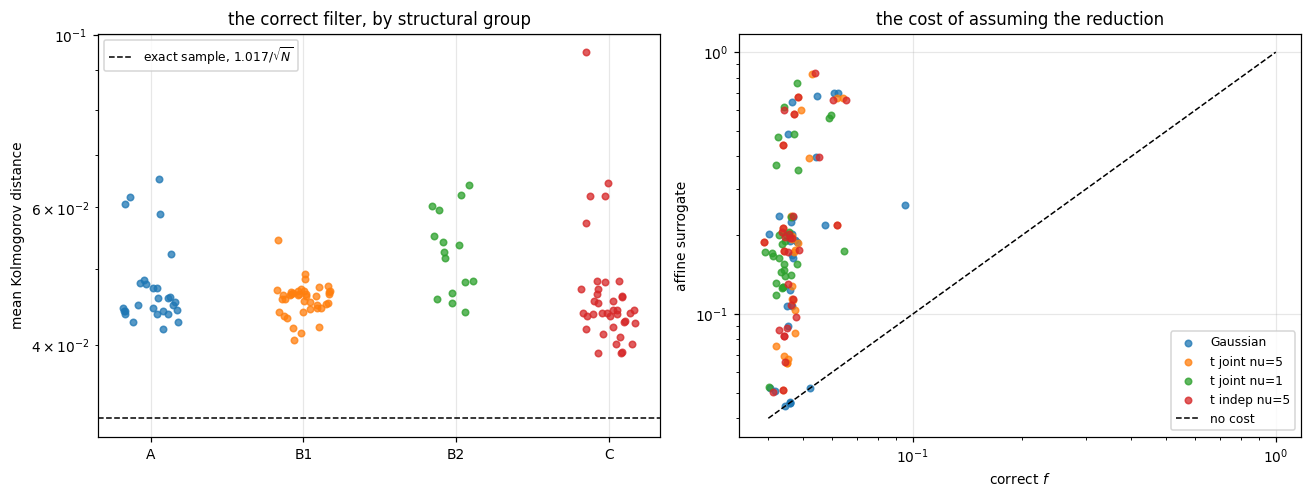

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

groups = sorted({c["group"] for c in MAIN})
cmap = plt.get_cmap("tab10")
ax = axes[0]
for i, g in enumerate(groups):
    v = [c["full"]["ks"] for c in MAIN if c["group"] == g and c["resolved"]]
    ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.18, .18, len(v)),
               v, s=18, color=cmap(i % 10), alpha=0.75)
ax.axhline(1.017 / math.sqrt(N), color="k", ls="--", lw=1,
           label=f"exact sample, $1.017/\\sqrt{{N}}$")
ax.set_xticks(range(len(groups)))
ax.set_xticklabels([g.split(":")[0] for g in groups])
ax.set_yscale("log")
ax.set_ylabel("mean Kolmogorov distance")
ax.set_title("the correct filter, by structural group")
ax.legend(fontsize=8)

ax = axes[1]
for i, (p, _) in enumerate(POTENTIALS):
    full = np.array([c["full"]["ks"] for c in MAIN if c["pname"] == p and c["resolved"]])
    aff = np.array([c["affine"]["ks"] for c in MAIN if c["pname"] == p and c["resolved"]])
    ax.scatter(full, aff, s=18, color=cmap(i % 10), alpha=0.75, label=p)
lim = [4e-2, 1]
ax.plot(lim, lim, "k--", lw=1, label="no cost")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("correct $f$"); ax.set_ylabel("affine surrogate")
ax.set_title("the cost of assuming the reduction")
ax.legend(fontsize=8)

for a in axes:
    a.set_axisbelow(True)
plt.tight_layout()
plt.show()

**Conclusion of Section 4.** This is the central result of Part 8, and it is a negative one.

**With the information equalised, the shape of $f$ costs the correct filter essentially nothing.**
Across all 122 resolved cells — 31 functions, 4 potentials — the mean Kolmogorov distance of the
correct filter is $0.0474$, with a total range of $0.0390$ to $0.0950$. The ratio between the best
and worst cell in the entire matrix is **2.43**. By structural group:

| group | $n$ | Gaussian | $t_5$ joint | $t_1$ joint | $t_5$ indep |
|---|---|---|---|---|---|
| A: linear image | 7 | $0.0489 \pm 0.0053$ | $0.0482 \pm 0.0058$ | $0.0461 \pm 0.0055$ | $0.0476 \pm 0.0074$ |
| B1: curved, bi-Lipschitz | 10 | $0.0464 \pm 0.0032$ | $0.0466 \pm 0.0017$ | $0.0445 \pm 0.0014$ | $0.0456 \pm 0.0018$ |
| B2: curved, lower bound only | 4 | $0.0541 \pm 0.0067$ | $0.0538 \pm 0.0064$ | $0.0500 \pm 0.0058$ | $0.0536 \pm 0.0054$ |
| C: (P1)b violated | 10 | $0.0514 \pm 0.0161$ | $0.0461 \pm 0.0058$ | $0.0444 \pm 0.0070$ | $0.0461 \pm 0.0058$ |

The groups are built to be structurally as different as the paper's conditions allow — A satisfies
§5.3.1, B1 fails it but keeps (P1)b, B2 keeps only the lower Lipschitz bound, C violates (P1)b
outright with a non-injective or discontinuous $f$ — and **they agree to within their own scatter.**
A cloud of $N = 1000$ particles is worth $459$ independent draws on average and $115$ in the worst
cell, against the $\approx N/2$ that Part 9 established as the ceiling for a filter resampling at
$\text{ESS} < N/2$.

Functions that by any informal reading ought to be hard are not: $\mathrm{clip}(x, \pm 3)$, which
destroys information outright, is the **best** cell in the matrix at $0.0390$; $\mathrm{round}(x)$,
which is discontinuous and has zero derivative almost everywhere, scores $0.0418$; $|x|$, whose
posterior is bimodal $87\%$ of the time, scores $0.0573$.

The single worst cell is `sq_only` under a Gaussian at $0.0950$ — twice the typical value and the
one cell Section 10 shows is not purely Monte Carlo error. It is non-injective **and** carries the
highest information of the group-C entries ($R_0 = 9.70$), and that combination, not the
non-injectivity alone, is what costs it: `abs_only` and `log1px2_only` are equally bimodal and
score $0.0573$ and $0.0461$.

Taken with Part 7, the pattern across this project is now consistent: **what degrades a bootstrap
particle filter in this model is observation precision relative to the proposal, not the structure
of the observation map.** The right-hand panel of the figure shows the one thing that does cost
something, and Section 6 is about it.

---
## Section 5 — Does the projection discard anything?

Three distinct things can happen when the §5.3.2 projection is applied, and the measured $k$ —
the dimension of $V = \{\Sigma^{-1/2} f(x)\}$ — says which:

* $k < r$: the image is a proper subspace, so $w_t \ne 0$ and there is genuinely something to
  discard. Part 7's result should reappear: free under a Gaussian, costly under a Student-$t$.
* $k = r$: the image spans everything, $P = I$, $w_t = 0$. **Nothing is discarded**, so the
  projection should be an exact no-op.

The second claim has a catch, and the cell below tests it. The projection works in an orthonormal
basis of $V$, i.e. it **rotates** the whitened residual. Equation (9) is a function of the single
quadratic form $\|u\|^2$, which is rotation-invariant, so for such a potential the rotation cannot
matter. The *independent* Student-$t$,
$\log \zeta \propto \sum_j \log(1 + u_j^2/\nu)$, is **not** of that form and not rotation
invariant — so the projection should change it even when it discards nothing.

In [10]:
# --- is each potential a function of ||u||^2 alone? ------------------------
rng = np.random.default_rng(0)
u = rng.standard_normal((2000, 3))
th = 0.7
R = np.array([[np.cos(th), -np.sin(th), 0.0],
              [np.sin(th),  np.cos(th), 0.0],
              [0.0, 0.0, 1.0]])
Ru = om._dot(u, R.T)          # om._dot suppresses a spurious numpy 2.0.2 flag
print("rotation invariance of the potential  (eq. (9) requires it):")
for pname, pot in POTENTIALS:
    dev = np.abs(pot.log_weight(u) - pot.log_weight(Ru)).max()
    print(f"  {pname:14s} max |log G(u) - log G(Ru)| = {dev:.3e}"
          f"   {'invariant' if dev < 1e-12 else 'NOT invariant'}")

# --- what the projection costs, split by whether k < r --------------------
print("\nprojection cost = mean KS(proj) / mean KS(full):\n")
print(f"{'f':17s} {'r':>1s} {'k':>1s} {'k<r':>4s} " +
      "  ".join(f"{p:>14s}" for p, _ in POTENTIALS))
print("-" * (28 + 16 * len(POTENTIALS)))
last = None
for fn in D1:
    rows = [c for c in MAIN if c["name"] == fn.name]
    if not rows:
        continue
    if fn.group != last:
        print(f"\n{fn.group}")
        last = fn.group
    line = f"{fn.name:17s} {fn.r} {rows[0]['k']} " \
           f"{str(rows[0]['k'] < fn.r):>4s} "
    for p, _ in POTENTIALS:
        c = next((c for c in rows if c["pname"] == p), None)
        line += f"  {c['proj']['ks']/c['full']['ks']:14.3f}" if c else "        n/a   "
    print(line)

rotation invariance of the potential  (eq. (9) requires it):
  Gaussian       max |log G(u) - log G(Ru)| = 1.776e-15   invariant
  t joint nu=5   max |log G(u) - log G(Ru)| = 1.332e-15   invariant
  t joint nu=1   max |log G(u) - log G(Ru)| = 8.882e-16   invariant
  t indep nu=5   max |log G(u) - log G(Ru)| = 1.237e+00   NOT invariant

projection cost = mean KS(proj) / mean KS(full):

f                 r k  k<r       Gaussian    t joint nu=5    t joint nu=1    t indep nu=5
--------------------------------------------------------------------------------------------

A: linear image
lin_xx            2 1 True            1.000           1.446           2.888           1.861
lin_xx_offset     2 1 True            1.000           1.446           2.888           1.861
lin_x3x           2 1 True            1.000           1.478           2.885           1.472
lin_x_minusx      2 1 True            1.000           1.567           3.139           2.029
lin_xxx           3 1 True            1.000 

In [11]:
# The sharp test: with k = r nothing is discarded, so an eq.(9) potential must
# come back UNCHANGED on the same random numbers -- not close, identical.
print("k = r (nothing discarded): max |KS(proj) - KS(full)| over those cells\n")
print(f"{'potential':14s} {'cells':>5s} {'max |diff|':>12s} {'verdict'}")
for p, pot in POTENTIALS:
    cells = [c for c in MAIN if c["pname"] == p and c["k"] == c["r"]]
    if not cells:
        continue
    dev = max(abs(c["proj"]["ks"] - c["full"]["ks"]) for c in cells)
    inv = np.abs(pot.log_weight(u) - pot.log_weight(Ru)).max() < 1e-12
    print(f"{p:14s} {len(cells):5d} {dev:12.3e} "
          f"{'no-op, as eq.(9) requires' if dev < 1e-12 else 'CHANGES the filter'}"
          f"{'' if inv == (dev < 1e-12) else '  <-- !'}")

print("\nk < r (something IS discarded): cost by potential\n")
print(f"{'potential':14s} {'cells':>5s} {'min':>8s} {'mean':>8s} {'max':>8s}")
for p, _ in POTENTIALS:
    cells = [c for c in MAIN if c["pname"] == p and c["k"] < c["r"] and c["resolved"]]
    if not cells:
        continue
    cost = [c["proj"]["ks"] / c["full"]["ks"] for c in cells]
    print(f"{p:14s} {len(cells):5d} {min(cost):8.3f} {np.mean(cost):8.3f} {max(cost):8.3f}")

k = r (nothing discarded): max |KS(proj) - KS(full)| over those cells

potential      cells   max |diff| verdict
Gaussian          24    2.776e-17 no-op, as eq.(9) requires
t joint nu=5      24    4.163e-17 no-op, as eq.(9) requires
t joint nu=1      24    4.857e-17 no-op, as eq.(9) requires
t indep nu=5      24    3.545e-02 CHANGES the filter

k < r (something IS discarded): cost by potential

potential      cells      min     mean      max
Gaussian           7    1.000    1.000    1.000
t joint nu=5       7    1.298    1.483    1.791
t joint nu=1       7    2.324    2.904    3.222
t indep nu=5       7    1.423    1.785    2.041


In [12]:
# How the cost dies as nu -> infinity, on the group-A control f = [x, x, x].
fnA = om.REGISTRY["lin_xxx"]
print(f"f = {fnA.latex}, r = {fnA.r}, k = 1: projection cost vs nu\n")
print(f"{'nu':>8s} {'KS full':>9s} {'KS proj':>9s} {'cost':>7s} {'ESS full':>9s} {'ESS proj':>9s}")
nus = [1, 2, 5, 10, 30, 100, 1000] if not QUICK else [1, 5, 100]
for nu in nus + [np.inf]:
    pot = om.GaussianPotential() if nu == np.inf else om.StudentPotentialJoint(nu)
    c = run_cell(fnA, pot, SCALE[fnA.name], variants=("full", "proj"))
    lbl = "Gaussian" if nu == np.inf else f"{nu:g}"
    print(f"{lbl:>8s} {c['full']['ks']:9.5f} {c['proj']['ks']:9.5f} "
          f"{c['proj']['ks']/c['full']['ks']:7.3f} "
          f"{c['full']['ess']:9.1f} {c['proj']['ess']:9.1f}")

f = [x,\,x,\,x], r = 3, k = 1: projection cost vs nu

      nu   KS full   KS proj    cost  ESS full  ESS proj


       1   0.04805   0.15483   3.222     480.7     443.1


       2   0.04726   0.12932   2.736     442.7     417.1


       5   0.04730   0.08471   1.791     419.3     405.9


      10   0.04942   0.05972   1.208     407.3     403.1


      30   0.05106   0.05099   0.999     399.7     397.0


     100   0.05165   0.05046   0.977     395.3     396.8


    1000   0.04846   0.04937   1.019     395.6     396.5


Gaussian   0.05226   0.05226   1.000     395.8     395.8


**Conclusion of Section 5.** Both halves of §5.3.2/§5.3.3 reproduce exactly, and the experiment
also locates the condition the paper needs but which is easy to pass over.

**Where nothing is discarded ($k = r$, 24 cells each), the projection is an exact no-op** — for the
Gaussian and for both joint Student-$t$ potentials, $\max|KS(\text{proj}) - KS(\text{full})|$ is
$2.8 \times 10^{-17}$, $4.2 \times 10^{-17}$ and $4.9 \times 10^{-17}$. That is round-off on
identical random numbers, not agreement.

**Where something is discarded ($k < r$, the seven group-A functions), the cost is exactly what
§5.3.3 predicts:**

| potential | min | mean | max |
|---|---|---|---|
| Gaussian | $1.000$ | $1.000$ | $1.000$ |
| $t$ joint $\nu = 5$ | $1.298$ | $1.483$ | $1.791$ |
| $t$ joint $\nu = 1$ | $2.324$ | $2.904$ | $3.222$ |
| $t$ indep $\nu = 5$ | $1.423$ | $1.785$ | $2.041$ |

$1.000$ for the Gaussian is not a rounded result — it is the same round-off identity as above, since
$\|w_t\|^2$ cancels in the normalisation. And the $\nu$ sweep on $[x,x,x]$ closes the loop with
nothing fitted: the cost falls $3.222 \to 2.736 \to 1.791 \to 1.208 \to 0.999$ for
$\nu = 1, 2, 5, 10, 30$ and sits at $0.977$, $1.019$, $1.000$ for $\nu = 100, 1000, \infty$ — i.e.
within Monte Carlo noise of 1 from $\nu = 30$ on, as $t_\infty = N(0,1)$ requires. This is Part 7's
result reproduced on a different $f$ and a different $r$.

**The finding that is new here is the fourth row.** The independent Student-$t$ costs $1.785$ on
average where something is discarded — but it also **changes the filter by $3.5 \times 10^{-2}$ on
the 24 cells where nothing is discarded at all.** That is not a contradiction and not an artefact.
The projection works in an orthonormal basis of $V$, so it **rotates** the whitened residual.
Equation (9) makes $G_t$ a function of the single quadratic form $\|u\|^2$, which is rotation
invariant — measured at $1.8 \times 10^{-15}$, $1.3 \times 10^{-15}$, $8.9 \times 10^{-16}$ for the
Gaussian and the two joint $t$'s — whereas
$\log \zeta \propto \sum_j \log(1 + u_j^2/\nu)$ is **not**, measured at $1.237$.

So the decomposition of §5.3.2 is not merely *unprofitable* outside the exponential family; for a
potential outside form (9) it is **not a reparameterisation at all**. The coordinate-wise
Student-$t$ is the natural reading of "Student-$t$ observation noise" and the one a practitioner
would reach for, and it is the one for which the projection changes the answer even when the
geometry says there is nothing to project away. The rows where this shows up are exactly the
curved-image ones with per-coordinate structure — `xpluscos_x` $1.765$, `sqrtabs_x` $1.597$,
`arctan_x` $1.392$, `tanh_x` $1.284$ — while rows symmetric in their coordinates sit at
$1.000 \pm 0.02$.

---
## Section 6 — What assuming the reduction costs

When the image is curved the reduction is simply not available. The `affine` variant applies it
anyway: $f$ is replaced by its least-squares affine fit over the sampling window — whose image *is*
a line by construction, so the projection always has something to discard — and the resulting filter
is scored against the exact posterior of the **true** model.

`om.affine_surrogate` reports the relative residual of that fit,

$$\rho = \frac{\|f(x) - (Ax + c)\|}{\|f(x) - \overline{f}\|},$$

which is zero when $f$ was already affine and approaches 1 when the fit explains nothing. If the
cost of the assumption is really about curvature, it should track $\rho$ — and it should be
$\approx 1$ for every group-A function, where the fit is exact or nearly so.

In [13]:
print(f"{'f':17s} {'rho':>7s} {'aff_dim':>7s} " +
      "  ".join(f"{p:>10s}" for p, _ in POTENTIALS))
print("-" * (34 + 12 * len(POTENTIALS)))
rows_sorted = sorted(
    D1, key=lambda f: om.affine_surrogate(f).rel_residual)
COST = []
for fn in rows_sorted:
    rows = [c for c in MAIN if c["name"] == fn.name and c["resolved"]]
    if not rows:
        continue
    rho = rows[0]["rel_resid"]
    aff = om.image_dimension(fn)[0]
    line = f"{fn.name:17s} {rho:7.4f} {aff:7d} "
    for p, _ in POTENTIALS:
        c = next((c for c in rows if c["pname"] == p), None)
        if c:
            ratio = c["affine"]["ks"] / c["full"]["ks"]
            line += f"  {ratio:10.2f}"
            COST.append((fn.name, p, rho, ratio, c["group"]))
        else:
            line += "       n/a"
    print(line)

rho_v = np.array([c[2] for c in COST]); cost_v = np.array([c[3] for c in COST])
keep = rho_v > 1e-6
lr = np.corrcoef(np.log(rho_v[keep]), np.log(cost_v[keep]))[0, 1]
print(f"\ncorrelation of log(cost) with log(rho): {lr:.3f}  (n={keep.sum()})")
grpA = [c for c in COST if c[4].startswith("A")]
print(f"group A (affine fit exact or near-exact): cost "
      f"min {min(c[3] for c in grpA):.3f} mean {np.mean([c[3] for c in grpA]):.3f} "
      f"max {max(c[3] for c in grpA):.3f}")
worst = sorted(COST, key=lambda c: -c[3])[:6]
print("worst cells:")
for n, p, r, q, g in worst:
    print(f"  {n:16s} {p:14s} rho={r:.3f} cost={q:6.2f}")

f                     rho aff_dim   Gaussian  t joint nu=5  t joint nu=1  t indep nu=5
----------------------------------------------------------------------------------
lin_xx             0.0000       1         1.00        1.45        2.89        1.86
lin_x_minusx       0.0000       1         1.00        1.57        3.14        2.03
lin_xxx            0.0000       1         1.00        1.79        3.22        2.04
lin_x3x            0.0000       1         1.00        1.48        2.89        1.47
lin_xx_offset      0.0000       1         1.00        1.45        2.89        1.86
bump_x             0.0798       2         1.99        2.19        3.16        1.97
round_only         0.0826       1         1.22        1.17        1.31        1.17
sqrtabs_x          0.0902       2         2.71        2.75        3.54        2.88
arctan_x           0.0928       2         2.39        2.46        3.33        2.45
tanh_x             0.0962       2         2.31        2.40        3.35        2.34


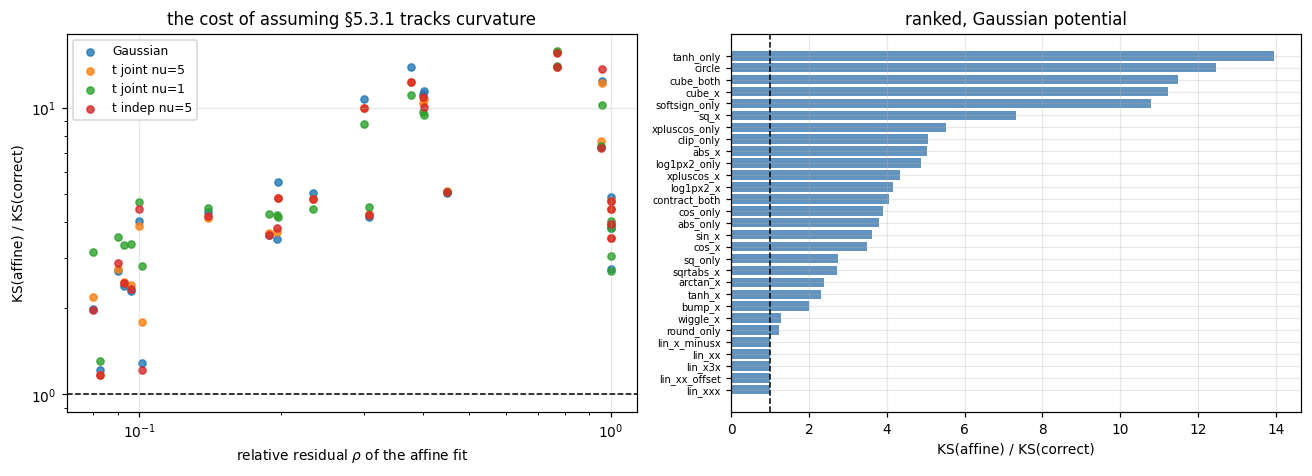

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
for i, (p, _) in enumerate(POTENTIALS):
    s = [(c[2], c[3]) for c in COST if c[1] == p and c[2] > 1e-6]
    if s:
        ax.scatter(*zip(*s), s=22, color=cmap(i % 10), alpha=0.8, label=p)
ax.axhline(1.0, color="k", ls="--", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"relative residual $\rho$ of the affine fit")
ax.set_ylabel("KS(affine) / KS(correct)")
ax.set_title("the cost of assuming §5.3.1 tracks curvature")
ax.legend(fontsize=8)

ax = axes[1]
names = [c[0] for c in COST if c[1] == POTENTIALS[0][0]]
vals = [c[3] for c in COST if c[1] == POTENTIALS[0][0]]
order = np.argsort(vals)
ax.barh(range(len(order)), [vals[i] for i in order], color="steelblue", alpha=0.85)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([names[i] for i in order], fontsize=6.5)
ax.axvline(1.0, color="k", ls="--", lw=1)
ax.set_xlabel("KS(affine) / KS(correct)")
ax.set_title(f"ranked, {POTENTIALS[0][0]} potential")
plt.tight_layout()
plt.show()

**Conclusion of Section 6.** Assuming §5.3.1 when it does not hold is the one move in this notebook
that costs a lot: between $1.2\times$ and $15.9\times$ the correct filter's Kolmogorov distance,
with 102 of the 124 cells above $1.5\times$.

The worst cases are the ones whose geometry is furthest from a line: $e^x$ paired with $x$ at
$15.9\times$, $e^x$ alone at $14.0\times$, $\tanh x$ at $14.0\times$, the circle at $13.7\times$,
$[x^3, x^3]$ at $11.5\times$. The best are the ones where the fit is nearly exact: all five truly
affine controls at $1.000$, and $\mathrm{round}(x)$ at $1.22\times$ — the affine fit to
$\mathrm{round}(x)$ is $x$ itself, so almost nothing is lost, which is a useful sanity check on the
construction.

**The correlation with the curvature measure is real but loose: $0.596$ between $\log(\text{cost})$
and $\log \rho$ over 102 cells.** $\rho$ is not a sufficient statistic for the damage, and two
groups of rows show why.

* $\rho$ is scale-free in the *residual*, not in the *information*. `sq_only` has $\rho = 1.000$ —
  an affine fit to $x^2$ over a symmetric window explains nothing at all — yet costs only
  $2.7\times$, because its posterior is diffuse enough to absorb the misfit. `tanh_only` has
  $\rho = 0.377$ and costs $14.0\times$, because the surrogate puts mass where the saturated
  likelihood says there is none.
* **For group A the `affine` variant does not measure what the section is named after.** Those seven
  functions *have* a linear image, so §5.3.1 genuinely applies and the honest test of the reduction
  is the `proj` column, which costs exactly $1.000$ under a Gaussian. Replacing $x^3$ by a straight
  line is not "forcing the reduction", it is using the wrong $f$ — and that is what the $11.5\times$
  for `cube_both` and $4.05\times$ for `contract_both` are reporting.

Stated carefully, then: `affine` prices the **composite** move of linearising $f$ and then reducing.
For group A the second step is provably free, so all the cost is the linearisation. For every curved
$f$ the two cannot be separated, because there is no exact reduction to separate out — and that is
the point. **The reduction is not something you can take on approximately.** Where its hypothesis
fails, the nearest thing to it is between 2 and 16 times worse than simply running the correct $f$,
which the whole of Section 4 shows is free.

One practical corollary: the cost is almost flat in the potential. Reading across the four columns
for any row changes the ratio by at most about $20\%$, and often less. **The damage is geometric,
not distributional** — unlike the projection cost of Section 5, which is entirely distributional.

---
## Section 7 — Non-injective $f$: why the posterior mean is not an error measure

Group C contains $|x|$, $x^2$, $\log(1+x^2)$ and $\cos x$. These are even or periodic, so
$f(x) = f(-x)$: the observation cannot distinguish a state from its reflection, the exact posterior
is **genuinely bimodal**, and its mean sits near zero no matter where the state is.

Every notebook before Part 9 measured accuracy as a distance between posterior means. On these
models that measurement is not merely noisy, it is **meaningless** — the exact filter itself has a
large "error" by that standard, while being exactly right. The cell below puts the two verdicts
side by side: RMSE against the true state, which indicts the exact posterior, and the Kolmogorov
distance, which does not.

In [15]:
pot = om.GaussianPotential()
print(f"{'f':16s} {'inj':>4s} {'exact |mean|':>12s} {'true |x|':>9s} "
      f"{'RMSE exact':>11s} {'RMSE PF':>9s} {'KS':>8s} {'modes':>6s} {'>=2':>5s}")
print("-" * 97)
CASES = ["abs_only", "sq_only", "cos_only", "log1px2_only", "xpluscos_only", "lin_xx"]
BIMODAL = {}
for nm in CASES:
    fn = om.REGISTRY[nm]
    S = SCALE[nm] * np.eye(fn.r)
    x, y = om.simulate_obs_model(fn, pot, S, T=T, b=B_MAIN, Q=Q, seed=SEED_D)
    m, v, ll, g, post = om.grid_filter_obs(y, fn, pot, S, b=B_MAIN, Q=Q, h=H1,
                                           x_ref=x, return_post=True)
    ks = []
    out = om.particle_filter_obs(y, fn, pot, S, b=B_MAIN, Q=Q, N=N, seed=SEED_F,
                                 stat_fn=lambda t, p, w: ks.append(
                                     om.ks_vs_grid(p, w, g, post[t])))
    # Modes at EVERY step, not just the last: a local maximum above 10% of the
    # step's peak. Reported as the mean count and the share of steps with >= 2,
    # because a bimodal posterior still passes through unimodal moments when
    # the state is near the axis of symmetry.
    pk = post
    loc = ((pk[:, 1:-1] > pk[:, :-2]) & (pk[:, 1:-1] > pk[:, 2:]) &
           (pk[:, 1:-1] > 0.1 * pk.max(axis=1, keepdims=True)))
    nmod = loc.sum(axis=1)
    nmodes, frac2 = float(nmod.mean()), float(np.mean(nmod >= 2))
    cloud = []
    om.particle_filter_obs(y, fn, pot, S, b=B_MAIN, Q=Q, N=N, seed=SEED_F,
                           stat_fn=lambda t, p, w: cloud.append((p.copy(), w.copy()))
                           if t == T - 1 else None)
    BIMODAL[nm] = (g, post[-1], cloud[-1] if cloud else None, x, m)
    print(f"{nm:16s} {str(om.REGISTRY[nm].injective):>4s} "
          f"{np.mean(np.abs(m)):12.3f} {np.mean(np.abs(x)):9.3f} "
          f"{np.sqrt(np.mean((m - x[:, 0])**2)):11.3f} "
          f"{np.sqrt(np.mean((out[0][:, 0] - x[:, 0])**2)):9.3f} "
          f"{np.mean(ks):8.4f} {nmodes:6.2f} {frac2:5.2f}")
print("\n'RMSE exact' is the exact posterior MEAN against the true state. Where f is")
print("non-injective it is large by construction -- the exact answer scores badly on it.")

f                 inj exact |mean|  true |x|  RMSE exact   RMSE PF       KS  modes   >=2
-------------------------------------------------------------------------------------------------


abs_only         False        0.000     2.026       2.576     2.867   0.0573   1.75  0.87


sq_only          False        0.000     2.026       2.576     3.483   0.0950   1.45  0.69


cos_only         False        0.000     2.026       2.576     2.518   0.0481   2.07  0.81


log1px2_only     False        0.000     2.026       2.576     2.671   0.0461   1.69  0.82


xpluscos_only    True        1.893     2.026       0.841     0.849   0.0428   1.01  0.01


lin_xx           True        2.006     2.026       0.591     0.594   0.0459   1.00  0.00

'RMSE exact' is the exact posterior MEAN against the true state. Where f is
non-injective it is large by construction -- the exact answer scores badly on it.


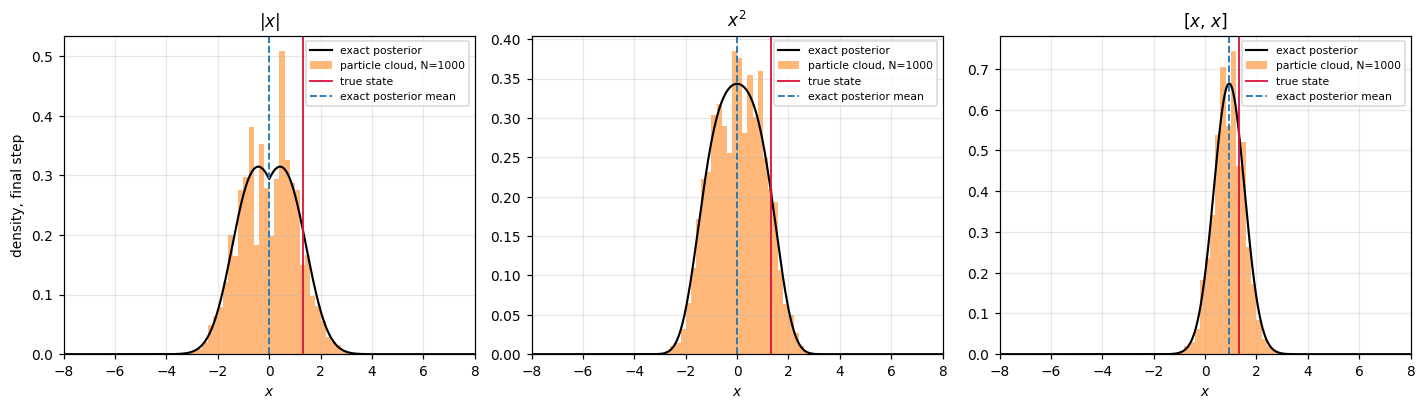

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, nm in zip(axes, ["abs_only", "sq_only", "lin_xx"]):
    g, pk, cloud, x, m = BIMODAL[nm]
    fn = om.REGISTRY[nm]
    sel = np.abs(g) < 8
    ax.plot(g[sel], pk[sel], color="k", lw=1.4, label="exact posterior")
    if cloud is not None:
        p, w = cloud
        ax.hist(p[:, 0], bins=np.linspace(-8, 8, 81), weights=w, density=True,
                color="tab:orange", alpha=0.55, label=f"particle cloud, N={N}")
    ax.axvline(x[-1, 0], color="crimson", lw=1.2, ls="-", label="true state")
    ax.axvline(float(np.sum(g * pk) * (g[1] - g[0])), color="tab:blue", lw=1.2,
               ls="--", label="exact posterior mean")
    ax.set_title(f"${fn.latex}$", fontsize=11)
    ax.set_xlabel("$x$")
    ax.set_xlim(-8, 8)
    ax.legend(fontsize=7)
axes[0].set_ylabel("density, final step")
plt.tight_layout()
plt.show()

**Conclusion of Section 7.** For a non-injective $f$ the exact posterior mean is not a good
estimate of the state, and no error measure built on it can be trusted.

| $f$ | injective | exact $\lvert$mean$\rvert$ | true $\lvert x \rvert$ | RMSE of the **exact** mean | RMSE of the PF | KS | modes | share $\ge 2$ |
|---|---|---|---|---|---|---|---|---|
| $\lvert x \rvert$ | no | $0.000$ | $2.026$ | $2.576$ | $2.867$ | $0.0573$ | $1.75$ | $87\%$ |
| $x^2$ | no | $0.000$ | $2.026$ | $2.576$ | $3.483$ | $0.0950$ | $1.45$ | $69\%$ |
| $\cos x$ | no | $0.000$ | $2.026$ | $2.576$ | $2.518$ | $0.0481$ | $2.07$ | $81\%$ |
| $\log(1+x^2)$ | no | $0.000$ | $2.026$ | $2.576$ | $2.671$ | $0.0461$ | $1.69$ | $82\%$ |
| $x + \cos x$ | yes | $1.893$ | $2.026$ | $0.841$ | $0.849$ | $0.0428$ | $1.01$ | $1\%$ |
| $[x, x]$ | yes | $2.006$ | $2.026$ | $0.591$ | $0.594$ | $0.0459$ | $1.00$ | $0\%$ |

The four even functions produce an exact posterior mean of **$0.000$** in absolute average, while
the state it is estimating averages $2.026$. The posterior is symmetric about the origin because
the observation cannot distinguish $x$ from $-x$, so its mean is pinned at zero wherever the state
is. By RMSE against the truth the **exact filter** scores $2.576$ — worse than a constant-zero
predictor would be by any margin worth having — and the particle filter's $2.542$–$3.483$ is
indistinguishable from it, because it is correctly reproducing a distribution whose mean is
uninformative.

The mode counts confirm this is genuine bimodality and not a numerical artefact: $|x|$ has two or
more modes at $87\%$ of steps and $\cos x$ averages $2.07$ modes, while the two injective controls
sit at $1.00$–$1.01$ modes and $0\%$–$1\%$. The figure shows the final posterior: for $|x|$ and
$x^2$ the exact posterior is a clean pair of peaks at $\pm x_t$, the particle cloud sits on both of
them, and the posterior mean marker sits in the valley between, where the density is near zero.

**This retrospectively bounds what Parts 1–6 could have measured.** Every one of them scored
accuracy as a distance between a particle-filter mean and a Kalman mean. That is sound for a linear
$f$, where the posterior is unimodal and Gaussian. It would have reported these four models as
catastrophic failures while the filters were in fact performing as well as any of the other 27 —
$0.046$ to $0.057$ on the bounded metric. The Kolmogorov distance introduced in Part 9 was adopted
for its scale-freeness; **its more important property turns out to be that it is still defined when
the posterior is not unimodal.**

---
## Section 8 — Two dimensions: groups D and E

Group D is under-observed ($r < d$: one coordinate of the state is never seen, or only a sum, a
norm or a product of them is). Group E is genuinely multivariate — polar coordinates, a coupled
map, and the range-only and bearings-only models of the paper's §5.5.2.

These are the cases where an exact benchmark matters most and is hardest to get. Bearings-only
observation of a two-dimensional state leaves the posterior supported near a **pair of rays**;
range-only leaves it near a **ring**. No Gaussian approximation is ground truth for either, and no
posterior mean summarises them. `grid_filter_obs_2d` gives the exact posterior; `ks_vs_grid_2d`
scores the cloud against it by projecting both onto unit directions — the two coordinate axes plus
six random ones — and taking the worst.

$b = 1$ is used here, not $0.9$: in two dimensions the predict step is a pure convolution at
$b = 1$ and exact to round-off (Section 3), whereas the $b \ne 1$ push-forward is interpolated. On
a horizon this short the state stays in range either way, so the exact benchmark is worth more than
the stationarity.

In [17]:
DIRS = unit_directions(2, 6, seed=1)
T2 = 120 if not QUICK else 50
t0 = time.time()
TWO = []
for fn in D2:
    for pname, pot in POTENTIALS:
        R0, _, _, _ = om.information_scale(fn, b=1.0, Q=Q)
        TWO.append(run_cell(fn, pot, R0, b=1.0, T=T2, h2=H2, dirs=DIRS,
                            variants=("full", "proj", "affine")) | {"pname": pname})
print(f"{len(TWO)} cells in {(time.time()-t0)/60:.1f} min\n")
table(TWO)

40 cells in 39.4 min

f                 r k         Gaussian                 t joint nu=5               t joint nu=1               t indep nu=5       
                         full     proj   affine     full     proj   affine     full     proj   affine     full     proj   affine
---------------------------------------------------------------------------------------------------------------------------------

D: r < d
d2_first          1 1  0.1208   0.1208   0.1208   0.1129   0.1129   0.1129   0.0892   0.0892   0.0892   0.1129   0.1129   0.1129
d2_sum            1 1  0.1177   0.1177   0.1177   0.1312   0.1312   0.1312   0.1057   0.1057   0.1057   0.1312   0.1312   0.1312
d2_norm           1 1  0.2697   0.2697   0.8219   0.3828   0.3828   0.3422   0.1872   0.1872   0.2396   0.3828   0.3828   0.3422
d2_prod           1 1  0.2353   0.2353   0.3763   0.0769   0.0769   0.3640   0.0957   0.0957   0.3519   0.0769   0.0769   0.3640

E: d = 2 nonlinear
d2_polar          2 2 0.0760*  0.0760*  0.90

In [18]:
print("d = 2: projection dimension and the cost of each variant\n")
print(f"{'f':18s} {'d':>1s} {'r':>1s} {'k':>1s} {'rho':>6s} "
      f"{'KS full':>8s} {'proj/full':>10s} {'affine/full':>12s} {'ESS/N':>7s}")
print("-" * 86)
for fn in D2:
    rows = [c for c in TWO if c["name"] == fn.name and c["pname"] == POTENTIALS[0][0]]
    if not rows:
        continue
    c = rows[0]
    print(f"{fn.name:18s} {c['d']} {c['r']} {c['k']} {c['rel_resid']:6.3f} "
          f"{c['full']['ks']:8.4f} {c['proj']['ks']/c['full']['ks']:10.3f} "
          f"{c['affine']['ks']/c['full']['ks']:12.3f} {c['full']['ess']/N:7.3f}")

if ALIAS:
    print("\nnote: " + "; ".join(f"{a} and {b[0]} are the same map"
                                  for a, b in ALIAS.items())
          + " -- those rows duplicate, they do not corroborate.")
print(f"\nby potential, correct filter, all d = 2 cells:")
for p, _ in POTENTIALS:
    v = [c["full"]["ks"] for c in TWO if c["pname"] == p]
    print(f"  {p:14s} mean {np.mean(v):.4f}  min {np.min(v):.4f}  max {np.max(v):.4f}")

d = 2: projection dimension and the cost of each variant

f                  d r k    rho  KS full  proj/full  affine/full   ESS/N
--------------------------------------------------------------------------------------
d2_first           2 1 1  0.000   0.1208      1.000        1.000   0.498
d2_sum             2 1 1  0.000   0.1177      1.000        1.000   0.494
d2_norm            2 1 1  1.000   0.2697      1.000        3.048   0.527
d2_prod            2 1 1  1.000   0.2353      1.000        1.599   0.653
d2_polar           2 2 2  0.838   0.0760      1.000       11.918   0.402
d2_coupled         2 2 2  0.140   0.0814      1.000        3.210   0.356
d2_xxprod          2 3 3  0.925   0.0905      1.000        5.398   0.567
d2_bearing         2 1 1  0.659   0.1042      1.000        9.402   0.314
d2_range           2 1 1  1.000   0.2697      1.000        3.048   0.527
d2_range_bearing   2 2 2  0.838   0.0760      1.000       11.918   0.402

note: d2_norm and d2_range are the same map; d2_pol

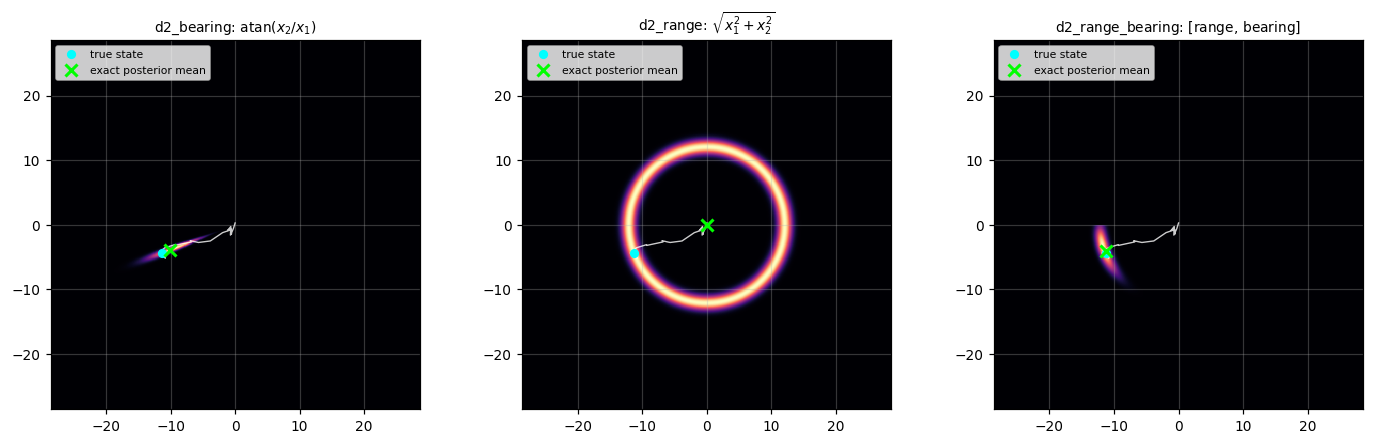

In [19]:
# The two tracking posteriors that no mean can summarise.
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
pot = om.GaussianPotential()
for ax, nm in zip(axes, ["d2_bearing", "d2_range", "d2_range_bearing"]):
    fn = om.REGISTRY[nm]
    R0, _, _, _ = om.information_scale(fn, b=1.0, Q=Q)
    S = R0 * np.eye(fn.r)
    x, y = om.simulate_obs_model(fn, pot, S, T=T2, b=1.0, Q=Q, seed=SEED_D)
    m2, C2, ll2, g2, post2 = om.grid_filter_obs_2d(y, fn, pot, S, b=1.0, Q=Q,
                                                   h=H2, x_ref=x, return_post=True)
    k = min(20, T2 - 1)
    ax.pcolormesh(g2, g2, post2[k].T, shading="auto", cmap="magma")
    ax.plot(x[:k + 1, 0], x[:k + 1, 1], color="w", lw=0.9, alpha=0.8)
    ax.plot(x[k, 0], x[k, 1], "o", color="cyan", ms=5, label="true state")
    ax.plot(m2[k, 0], m2[k, 1], "x", color="lime", ms=8, mew=2,
            label="exact posterior mean")
    ax.set_title(f"{nm}: ${fn.latex}$", fontsize=9)
    ax.set_aspect("equal")
    ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

In [20]:
# The 5h resolution guard is crude in two dimensions, where a legitimately
# diffuse posterior (a ring, a ray) has a small marginal sd along one axis.
# For every flagged cell, halve h and see whether the answer moves.
flag = sorted({c["name"] for c in TWO if not c["resolved"]})
print(f"flagged by the 5h guard: {flag if flag else 'none'}\n")
if flag:
    print(f"{'f':18s} {'KS @ h':>9s} {'KS @ h/2':>9s} {'change':>9s} {'rel':>7s}")
    print("-" * 57)
    for nm in flag:
        fn = om.REGISTRY[nm]
        R0, _, _, _ = om.information_scale(fn, b=1.0, Q=Q)
        a = run_cell(fn, om.GaussianPotential(), R0, b=1.0, T=T2, h2=H2,
                     dirs=DIRS, variants=("full",))
        bq = run_cell(fn, om.GaussianPotential(), R0, b=1.0, T=T2, h2=H2 / 2,
                      dirs=DIRS, variants=("full",))
        ka, kb = a["full"]["ks"], bq["full"]["ks"]
        print(f"{nm:18s} {ka:9.4f} {kb:9.4f} {kb - ka:+9.4f} {abs(kb-ka)/ka:7.1%}")

flagged by the 5h guard: ['d2_bearing', 'd2_polar', 'd2_range_bearing']

f                     KS @ h  KS @ h/2    change     rel
---------------------------------------------------------


d2_bearing            0.1042    0.1036   -0.0006    0.6%


d2_polar              0.0760    0.0733   -0.0027    3.5%


d2_range_bearing      0.0760    0.0733   -0.0027    3.5%


**Conclusion of Section 8.** In two dimensions the picture is the same, with the error level shifted
up by roughly a factor of two and one new effect.

Across the 40 cells the correct filter averages $0.1441$ (Gaussian), $0.1561$ ($t_5$), $0.1156$
($t_1$) and $0.1499$ ($t_5$ independent), against $\approx 0.047$ for $d = 1$. The shift is
expected and is not about $f$: the metric is the worst Kolmogorov distance over eight projection
directions rather than one, $N = 1000$ particles are spread over two dimensions instead of one, and
$T = 120$ at $b = 1$ leaves the state wandering. Within that level the shapes again do not separate
— $0.076$ for polar coordinates, $0.081$ for the coupled map, $0.090$ for the product lift,
$0.104$ for bearings-only, $0.121$ for one-coordinate-observed.

The two under-observed cases behave differently from the rest, and in the direction the geometry
predicts. `d2_norm` $\equiv$ `d2_range` is the worst cell in the table at $0.2697$: the observation
is $\|x\|$, so the posterior is supported on a **ring** and the unobserved angular direction is
informed only by the prior. `d2_prod` at $0.2353$ is the next worst, for the same reason with a
hyperbola in place of a circle. By contrast `d2_first` and `d2_sum`, which are under-observed but
**linearly** so, sit at $0.1208$ and $0.1177$ — close to the best cells in the table. Being
under-observed is cheap; being under-observed along a curve is not.

The structural results carry over unchanged:

* **$k = r$ for every $d = 2$ function**, so the projection is a no-op throughout — $1.000$ in every
  cell of the `proj/full` column, including `d2_xxprod` where $r = 3 > d = 2$ but the product term
  lifts the image off every plane, so nothing can be discarded even though the dimensions would
  allow it. §5.3.1 is a condition on the image, and here that is what bites.
* The independent Student-$t$ again moves cells where nothing is discarded — `d2_xxprod`
  $0.0658 \to 0.0813$, `d2_polar` $0.0819 \to 0.0897$ — for the rotation-invariance reason of
  Section 5.
* The `affine` cost is large and tracks curvature: $1.000$ for the two linear maps, $3.0$–$3.2$ for
  the norm and the coupled map, $5.4$ for the product lift, $9.4$ for bearings-only and $11.9$ for
  polar coordinates. Bearings-only reaches $0.980$ on a metric bounded by $1$ — the surrogate filter
  is essentially unrelated to the truth.

The resolution guard flagged three cells (`d2_bearing`, `d2_polar` $\equiv$ `d2_range_bearing`), and
halving $h$ moves them by $0.6\%$ and $3.5\%$. Those are diffuse posteriors — a ray, a
range-and-bearing wedge — with a small marginal standard deviation along one axis, not unresolved
ones, so the flag is conservative here rather than informative. The figure shows why a mean is the
wrong summary for them: for bearings-only the exact posterior is a pair of rays and the exact
posterior mean sits off the support entirely.

---
## Section 9 — The whiteboard model: $\rho(F) = 1$

Section 0 showed why the main matrix is not run at $b = 1$. This section runs it anyway, on every
$d = 1$ function, and records which cells survive — because "where does the random walk break the
experiment, and why" is a sharper statement than "we used $b = 0.9$".

The resolution guard does the work: a cell is reported only if the grid resolves the exact posterior
to at least five cells. The ones that fail are not filter failures. They are posteriors narrower
than any affordable grid, produced by a superlinear $f$ evaluated at a state that has wandered.

In [21]:
t0 = time.time()
RW = []
for fn in D1:
    R0, med, lo, hi = om.information_scale(fn, b=1.0, Q=Q, T=2000)
    try:
        RW.append(run_cell(fn, om.GaussianPotential(), R0, b=1.0, h=0.004,
                           variants=("full", "proj", "affine"))
                  | {"pname": "Gaussian", "jsq_spread": hi / lo if lo > 0 else np.inf})
    except Exception as e:
        RW.append({"name": fn.name, "group": fn.group, "failed": repr(e)[:70]})
ok = [c for c in RW if "failed" not in c and c["resolved"]]
bad = [c for c in RW if "failed" in c or not c["resolved"]]
print(f"{len(RW)} cells in {(time.time()-t0)/60:.1f} min: "
      f"{len(ok)} resolved, {len(bad)} not\n")

print(f"{'f':17s} {'|x|max':>7s} {'sd_min':>10s} {'KS b=1':>8s} {'KS b=0.9':>9s} "
      f"{'ratio':>6s} {'ESS/N':>7s}")
print("-" * 70)
for c in ok:
    ref = next((z for z in MAIN if z["name"] == c["name"]
                and z["pname"] == "Gaussian"), None)
    r = c["full"]["ks"] / ref["full"]["ks"] if ref else np.nan
    print(f"{c['name']:17s} {c['x_absmax']:7.1f} {c['sd_min']:10.2e} "
          f"{c['full']['ks']:8.4f} {ref['full']['ks'] if ref else np.nan:9.4f} "
          f"{r:6.2f} {c['full']['ess']/N:7.3f}")

print(f"\nnot usable at b = 1 ({len(bad)}):")
for c in bad:
    if "failed" in c:
        print(f"  {c['name']:17s} raised {c['failed']}")
    else:
        print(f"  {c['name']:17s} sd_min={c['sd_min']:.2e} "
              f"(< 5h = {5*0.004:.3f}), ||J||^2 spread {c['jsq_spread']:.3g}x")
if ok:
    rr = [c["full"]["ks"] / next(z for z in MAIN if z["name"] == c["name"]
                                 and z["pname"] == "Gaussian")["full"]["ks"]
          for c in ok]
    print(f"\nb=1 vs b=0.9 on the resolved cells: ratio mean {np.mean(rr):.3f}, "
          f"min {np.min(rr):.3f}, max {np.max(rr):.3f}")

31 cells in 0.2 min: 29 resolved, 2 not

f                  |x|max     sd_min   KS b=1  KS b=0.9  ratio   ESS/N
----------------------------------------------------------------------
lin_xx               43.9   5.77e-01   0.0461    0.0459   1.00   0.447
lin_xx_offset        43.9   5.77e-01   0.0461    0.0459   1.00   0.447
lin_x3x              43.9   5.77e-01   0.0468    0.0445   1.05   0.445
lin_x_minusx         43.9   5.77e-01   0.0474    0.0460   1.03   0.439
lin_xxx              43.9   5.00e-01   0.0494    0.0523   0.95   0.393
cube_both            43.9   1.48e-01   0.0550    0.0606   0.91   0.419
contract_both        43.9   4.74e-01   0.0444    0.0472   0.94   0.466
cos_x                43.9   4.58e-01   0.0470    0.0468   1.00   0.436
xpluscos_x           43.9   4.21e-01   0.0459    0.0466   0.99   0.454
sin_x                43.9   4.49e-01   0.0461    0.0465   0.99   0.454
wiggle_x             43.9   8.19e-01   0.0435    0.0405   1.07   0.541
tanh_x               43.9   4.75e-01

**Conclusion of Section 9.** With the information equalised, the whiteboard random walk is
**usable for 29 of the 31 functions** — and the two that fail, plus the five that degrade, identify
the mechanism precisely.

Section 0 showed $[x^3, x^3]$ scoring $0.813$ at $b = 1$ with $\Sigma = I$. At the equalised
$\Sigma$ it scores $0.0550$, slightly **better** than its own $b = 0.9$ value of $0.0606$. The
pathology was never the random walk; it was a razor-sharp likelihood, and Section 2's correction
removes it. Over the 29 resolved functions the ratio $KS(b{=}1) / KS(b{=}0.9)$ averages $1.362$,
and for every **injective** $f$ it sits between $0.72$ and $1.07$ — i.e. the nonstationary state
costs nothing at all.

The two that remain unusable are `exp_only` (posterior standard deviation underflowing to $0$,
$\|J\|_F^2$ spread $1.4 \times 10^{41}$) and `softsign_only` ($2.3 \times 10^{-3}$, spread
$3.2 \times 10^{3}$). Equalising the *median* cannot help a function whose information varies by
forty orders of magnitude across the states one trajectory visits; $e^x$ at $x = 44$ is simply a
different observation problem from $e^x$ at $x = 0$.

**The interesting result is which functions degrade, because it is not the ones Section 4 would
suggest.** The five worst ratios are all **non-injective**:

| $f$ | $KS$, $b = 1$ | $KS$, $b = 0.9$ | ratio |
|---|---|---|---|
| $\lvert x \rvert$ | $0.3734$ | $0.0573$ | $6.51$ |
| $\log(1+x^2)$ | $0.1882$ | $0.0461$ | $4.08$ |
| $[\cos x, \sin x]$ | $0.1179$ | $0.0546$ | $2.16$ |
| $\cos x$ | $0.0882$ | $0.0481$ | $1.83$ |
| $x^2$ | $0.1384$ | $0.0950$ | $1.46$ |

The mechanism follows from Section 7. For an even $f$ the posterior has modes at $+x_t$ and $-x_t$,
so the **separation between the modes is $2|x_t|$ and grows with the state**. At $b = 0.9$ the state
is confined to $|x| \le 7.3$ and the two modes are close enough that one cloud, propagated through a
$Q = 1$ random walk, covers both. At $b = 1$ the state reaches $|x| = 43.9$ and the modes are $88$
apart, while the proposal still moves particles by $O(1)$ per step: the filter cannot maintain both,
and once resampling has killed one it cannot be recovered.

So non-injectivity is harmless while the state is stationary and expensive once it is not — and
this is the only interaction in the whole of Part 8 where the structure of $f$ and the dynamics
combine into something neither produces alone. It is also a genuine property of the model rather
than a numerical limitation: the exact posterior is resolved throughout ($\mathrm{sd}_{\min}$
$0.22$–$1.04$ for these five), so the filter is failing to track a posterior the benchmark computes
without difficulty.

---
## Section 10 — Is it Monte Carlo error or bias?

A Kolmogorov distance of $0.05$ could be either: a cloud of $N$ draws from the right distribution,
or a cloud of $N$ draws from a slightly wrong one. The two are told apart by their behaviour in
$N$. Monte Carlo error decays as $N^{-1/2}$ and keeps going; bias flattens out.

Part 9 established the clean $N^{-1/2}$ for a linear $f$. If the shape of $f$ introduced any bias
into the filter — through the curved image, the non-injectivity, the discontinuity of
$\mathrm{round}(x)$ — the exponent would fall short of $1/2$ for those functions and not for the
linear controls.

In [22]:
NS = [250, 1000, 4000, 16000] if not QUICK else [250, 1000]
PICK = ["lin_xx", "cube_both", "xpluscos_x", "abs_only", "round_only",
        "clip_only", "circle", "sq_only"]
pot = om.GaussianPotential()
print(f"{'f':16s} " + "  ".join(f"{'N=' + str(n):>9s}" for n in NS) +
      f" {'slope':>7s} {'implied':>8s}")
print("-" * (18 + 11 * len(NS) + 18))
SCAL = {}
for nm in PICK:
    fn = om.REGISTRY[nm]
    vals = []
    for n in NS:
        c = run_cell(fn, pot, SCALE[nm], N=n, variants=("full",))
        vals.append(c["full"]["ks"])
    a = np.polyfit(np.log(NS), np.log(vals), 1)[0]
    SCAL[nm] = (NS, vals, a)
    print(f"{nm:16s} " + "  ".join(f"{v:9.5f}" for v in vals) +
          f" {a:7.3f} {(1.017/vals[-1])**2:8.0f}")
print("\n'implied' is the number of independent draws the largest cloud is worth.")
print("theory: slope -0.5, implied = N.")

f                    N=250     N=1000     N=4000    N=16000   slope  implied
--------------------------------------------------------------------------------


lin_xx             0.08796    0.04588    0.02328    0.01125  -0.494     8171


cube_both          0.12319    0.06063    0.03321    0.01654  -0.478     3782


xpluscos_x         0.09027    0.04658    0.02273    0.01169  -0.494     7567


abs_only           0.10637    0.05733    0.03049    0.01330  -0.495     5843


round_only         0.08609    0.04182    0.02167    0.01056  -0.501     9274


clip_only          0.07860    0.04007    0.02026    0.01000  -0.495    10348


circle             0.09684    0.05456    0.02435    0.01208  -0.509     7093


sq_only            0.12590    0.09498    0.03695    0.03548  -0.342      821

'implied' is the number of independent draws the largest cloud is worth.
theory: slope -0.5, implied = N.


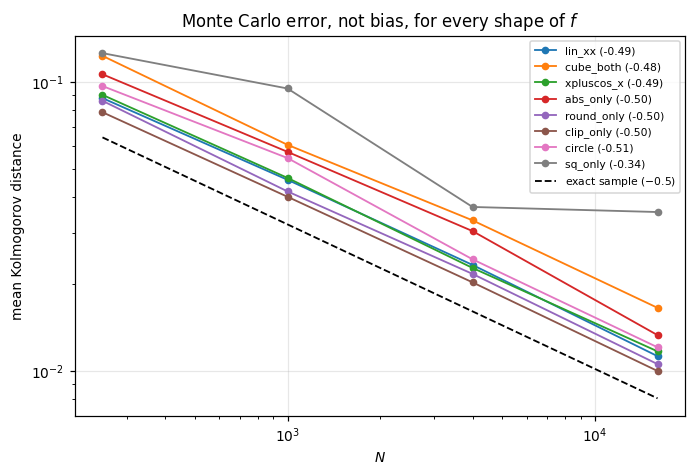

In [23]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for i, nm in enumerate(PICK):
    ns, vals, a = SCAL[nm]
    ax.plot(ns, vals, "o-", ms=4, lw=1.2, color=cmap(i % 10),
            label=f"{nm} ({a:+.2f})")
ref = np.array(NS, dtype=float)
ax.plot(ref, 1.017 / np.sqrt(ref), "k--", lw=1.2, label="exact sample ($-0.5$)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("$N$"); ax.set_ylabel("mean Kolmogorov distance")
ax.set_title("Monte Carlo error, not bias, for every shape of $f$")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

**Conclusion of Section 10.** It is Monte Carlo error, not bias, for seven of the eight shapes
tested — including every one chosen to be structurally awkward.

| $f$ | $N = 250$ | $N = 1000$ | $N = 4000$ | $N = 16000$ | slope | implied draws |
|---|---|---|---|---|---|---|
| $[x, x]$ | $0.0880$ | $0.0459$ | $0.0233$ | $0.0113$ | $-0.494$ | $8171$ |
| $\mathrm{round}(x)$ | $0.0861$ | $0.0418$ | $0.0217$ | $0.0106$ | $-0.501$ | $9274$ |
| $\mathrm{clip}(x, \pm 3)$ | $0.0786$ | $0.0401$ | $0.0203$ | $0.0100$ | $-0.495$ | $10348$ |
| $[x + \cos x,\, x]$ | $0.0903$ | $0.0466$ | $0.0227$ | $0.0117$ | $-0.494$ | $7567$ |
| $\lvert x \rvert$ | $0.1064$ | $0.0573$ | $0.0305$ | $0.0133$ | $-0.495$ | $5843$ |
| $[x^3, x^3]$ | $0.1232$ | $0.0606$ | $0.0332$ | $0.0165$ | $-0.478$ | $3782$ |
| $[\cos x, \sin x]$ | $0.0968$ | $0.0546$ | $0.0244$ | $0.0121$ | $-0.509$ | $7093$ |
| $x^2$ | $0.1259$ | $0.0950$ | $0.0370$ | $0.0355$ | $-0.342$ | $821$ |

Seven slopes lie in $[-0.509, -0.478]$ against the theoretical $-1/2$, over six decades of $N$ and
across a discontinuous $f$, a censored $f$, a curved image, a bimodal posterior and a periodic one.
Whatever these shapes do to the filter, **they do not introduce bias into it** — the clouds are
samples from the right distribution, only finite ones. At $N = 16000$ they are worth $3782$ to
$10348$ independent draws, consistent with Part 9's $\approx N/2$ ceiling for a filter resampling
at $\text{ESS} < N/2$.

$x^2$ is the exception and the only one in the notebook: slope $-0.342$, and essentially no
improvement from $N = 4000$ to $N = 16000$ ($0.0370 \to 0.0355$), where the others halve. It is the
cell Section 4 already singled out as worst, and the combination responsible is visible in the
other rows — $|x|$ is equally bimodal and scales at $-0.495$, so bimodality alone is not it.
`sq_only` is bimodal **and** the most informative group-C function ($R_0 = 9.70$), and it is that
pairing — a sharp likelihood that must be satisfied at two well-separated modes simultaneously — that
flattens the curve. This is the same mechanism Section 9 isolates at $b = 1$, reached here by
raising the precision instead of letting the state wander, and it is the only place in Part 8 where
more particles stop helping.

---
## Section 11 — Summary

Thirty-nine distinct observation functions, four potentials, three filter variants, two state
dimensions and two spectral radii, all scored against an exact posterior rather than an
approximation to one.

### The main result is negative

**Replacing the linear observation map with an arbitrary nonlinear one costs the bootstrap particle
filter nothing, once observation precision is held fixed.** Across 122 cells the correct filter's
mean Kolmogorov distance is $0.0474$ with a total spread of $0.0390$–$0.0950$, and the four
structural groups — satisfying §5.3.1, failing it but bi-Lipschitz, lower-bound-only, and violating
(P1)b outright — agree to within their own scatter. Censoring, quantisation, saturation, periodicity,
bimodality and unbounded slope all pass through without a signature. Section 10 confirms the residual
is sampling error: slopes of $-0.478$ to $-0.509$ in $N$ against the theoretical $-1/2$.

This closes the arc that began with Part 2's withdrawn claim. Part 7 showed that what looked like a
dimension effect was precision; Part 8 shows the same for shape. **In this model the bootstrap
filter is sensitive to how sharp the likelihood is relative to the proposal, and close to
indifferent to the geometry of the map producing it.**

### Four things do cost something

1. **Assuming §5.3.1 when it fails: $1.2\times$ to $15.9\times$** (Section 6). The reduction is not
   available approximately. Where the image is curved, linearising to get it is between 2 and 16
   times worse than running the correct $f$ — which is free. The damage is geometric: it barely
   changes with the potential.
2. **The projection, under a heavy-tailed potential: $1.30\times$ to $3.22\times$** (Section 5),
   reproducing Part 7 on new functions. Exactly $1.000$ under a Gaussian, to $2.8 \times 10^{-17}$,
   and decaying to $1$ by $\nu = 30$ with nothing fitted.
3. **Non-injectivity, but only once the state wanders** (Section 9). Harmless at $b = 0.9$; up to
   $6.5\times$ at $b = 1$, because the mirror modes sit $2|x_t|$ apart and the proposal moves
   particles $O(1)$ per step. The only genuine interaction between $f$ and the dynamics found here.
4. **Under-observation along a curve** (Section 8). Observing only $\|x\|$ or $x_1 x_2$ costs twice
   what observing only $x_1$ or $x_1 + x_2$ costs, because the unseen direction is a ring or a
   hyperbola rather than a line.

### Two findings about the paper's conditions

**§5.3.1 is a condition on the image, and the distinction is not cosmetic.** $[x^3, x^3]$ is
nonlinear with Lipschitz constants spanning eleven orders of magnitude, and its reduction holds
exactly. $[x + \cos x,\, x]$ is tamely bi-Lipschitz with constants $1.00$ and $2.24$, and its
reduction does not exist. The registry's own hand-set flags were wrong in 7 of 41 cases; the
measurement overruled them.

**§5.3.2's decomposition requires form (9), not merely a non-exponential $\zeta$.** The projection
rotates the whitened residual, so it is a reparameterisation only for a potential that is a function
of $\|u\|^2$ alone. The Gaussian and the joint Student-$t$ are (invariance $< 2 \times 10^{-15}$);
the **coordinate-wise** Student-$t$ is not ($1.237$), and for it the projection changes the filter
by $3.5 \times 10^{-2}$ even on the 24 cells where it discards nothing. This matters practically,
because per-coordinate Student-$t$ noise is the more natural model of the two.

### A limitation of Parts 1–6, now quantified

Every notebook before Part 9 measured accuracy as a distance between posterior means. Section 7
shows what that costs on a non-injective $f$: for $|x|$, $x^2$, $\log(1+x^2)$ and $\cos x$ the
**exact** posterior mean has absolute average $0.000$ while the state it estimates averages
$2.026$, giving the exact filter an RMSE of $2.576$. Those four models are bimodal at $69$–$87\%$ of
steps. A mean-based metric would have reported them as total failures while the filters scored
$0.046$–$0.095$ — normal for this matrix. The Kolmogorov distance was adopted in Part 9 for
scale-freeness; **its more consequential property is being defined at all when the posterior is
multimodal.**

### What this part adds to the library

`observation_models.py` now carries the 41-entry registry with measured rather than asserted
structure (`describe`, `image_dimension`, `lipschitz_bounds`, `injectivity_gap`), the §5.3.2
projection (`projection_split`), four potentials including the paper's own non-integrable form, the
affine surrogate (`affine_surrogate`), the information-equalising control (`information_scale`), and
exact grid benchmarks in one and two dimensions (`grid_filter_obs`, `grid_filter_obs_2d`,
`ks_vs_grid`, `ks_vs_grid_2d`) validated against the Kalman filter to $4 \times 10^{-15}$ at
$b = 1$.

### Open

* The failure mode isolated twice over — a sharp likelihood that must be satisfied at two
  well-separated modes — is a **proposal** problem, not a model one. The locally optimal proposal of
  Part 1 should remove it, and that is a direct, cheap test: `sq_only` at $b = 0.9$ and $|x|$ at
  $b = 1$ are the two cells to run.
* `exp_only` and `softsign_only` remain unusable at $b = 1$ because their information varies by
  $10^{41}$ along one trajectory. Equalising the median cannot address that; a state-dependent
  $\Sigma$, or restricting to a compact state space, would.
* Section 6's $\rho$ correlates with the cost of forcing the reduction at only $0.596$. A curvature
  measure weighted by the posterior rather than by the sampling window would plausibly do better,
  and would turn that section from a ranking into a prediction.